<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/Python%20Code_MuMax3%20Data%20Plots/STT_Switching_Simulation_on_MgO_CFB_pMTJ_in_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

The following table defines the foundational parameters alongside their required SI units for the MuMax3 execution.

| Physical Parameter | Script Variable | Standard SI Unit | Unit Symbol |
| --- | --- | --- | --- |
| Spatial dimension | `sizeX`, `sizeY`, `sizeZ` | meters | m |
| Grid discretization | `Nx`, `Ny` | dimensionless | $N_x, N_y$ |
| Volume saturation magnetization | `Msat` | amperes per meter | A/m |
| Exchange stiffness constant | `Aex` | joules per meter | J/m |
| Gilbert damping constant | `alpha` | dimensionless | $\alpha$ |
| Normalized initial magnetization | `m` | dimensionless | $\mathbf{m}$ |
| Slonczewski asymmetry parameter | `lambda` | dimensionless | $\Lambda$ |
| Spin polarization fraction | `Pol` | dimensionless | $P$ |
| Secondary Slonczewski parameter | `epsilonprime` | dimensionless | $\epsilon'$ |
| In-plane geometrical angle | `angle` | degrees | ° |
| Fixed layer polarization vector | `fixedlayer`, `px`, `py` | dimensionless | $\mathbf{p}$ |
| Total electrical current | `Jtot` | amperes | A |
| Cross-sectional area | `area` | square meters | m² |
| Electrical current density | `jc`, `J` | amperes per square meter | A/m² |
| Integration time periods | `autosave`, `tableautosave`, `run` | seconds | s |

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Geometry interpretation
  MuMax3 expression: circle(sizeX)
  Matplotlib projection: Circular Free Layer
  box: 40.000 x 40.000 x 1.700 nm
  mesh cell: 1.250 x 1.250 nm in plane
  current cross section: 1256.637061 nm^2
  exchange length: 5.641896 nm
  applied current: +122.500000 uA
  applied current density: +9.748240 MA/cm^2
  macrospin Ic0 consistency check: 20.994722 uA
  current overdrive versus model Ic0: 5.834800 x
  approximate deterministic switching time: 1.698089 ns
  write-pulse duration: 4.000000 ns
  electrical switching energy: unavailable until a measured RA product is supplied
MuMax3 simulation controls
  device: single-interface CoFeB/MgO/CoFeB p-MTJ
  geometry: Circular Free Layer | D=40.000 nm | grid=32 x 32 x 1
  layers: reference CoFeB=1.000 nm | MgO=0.850 nm | free CoFeB=1.700 

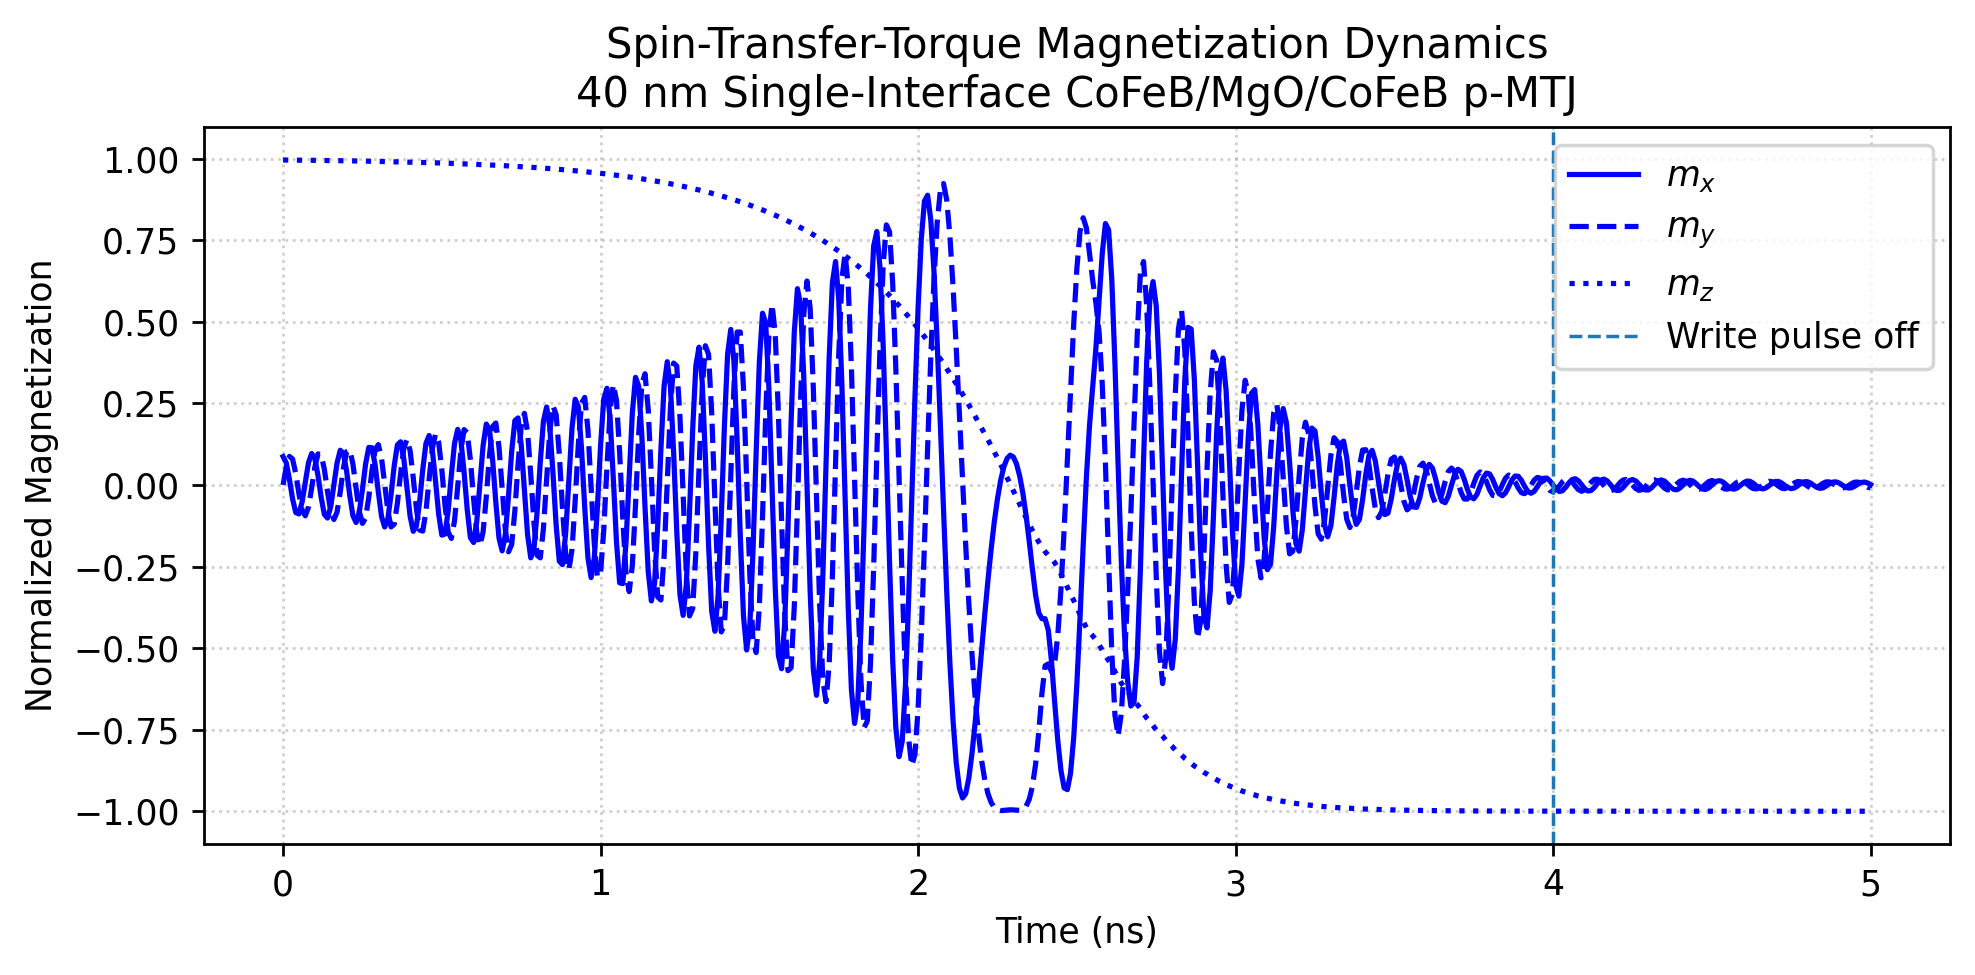

Converted 10 selected OVF snapshots in 0.046 s


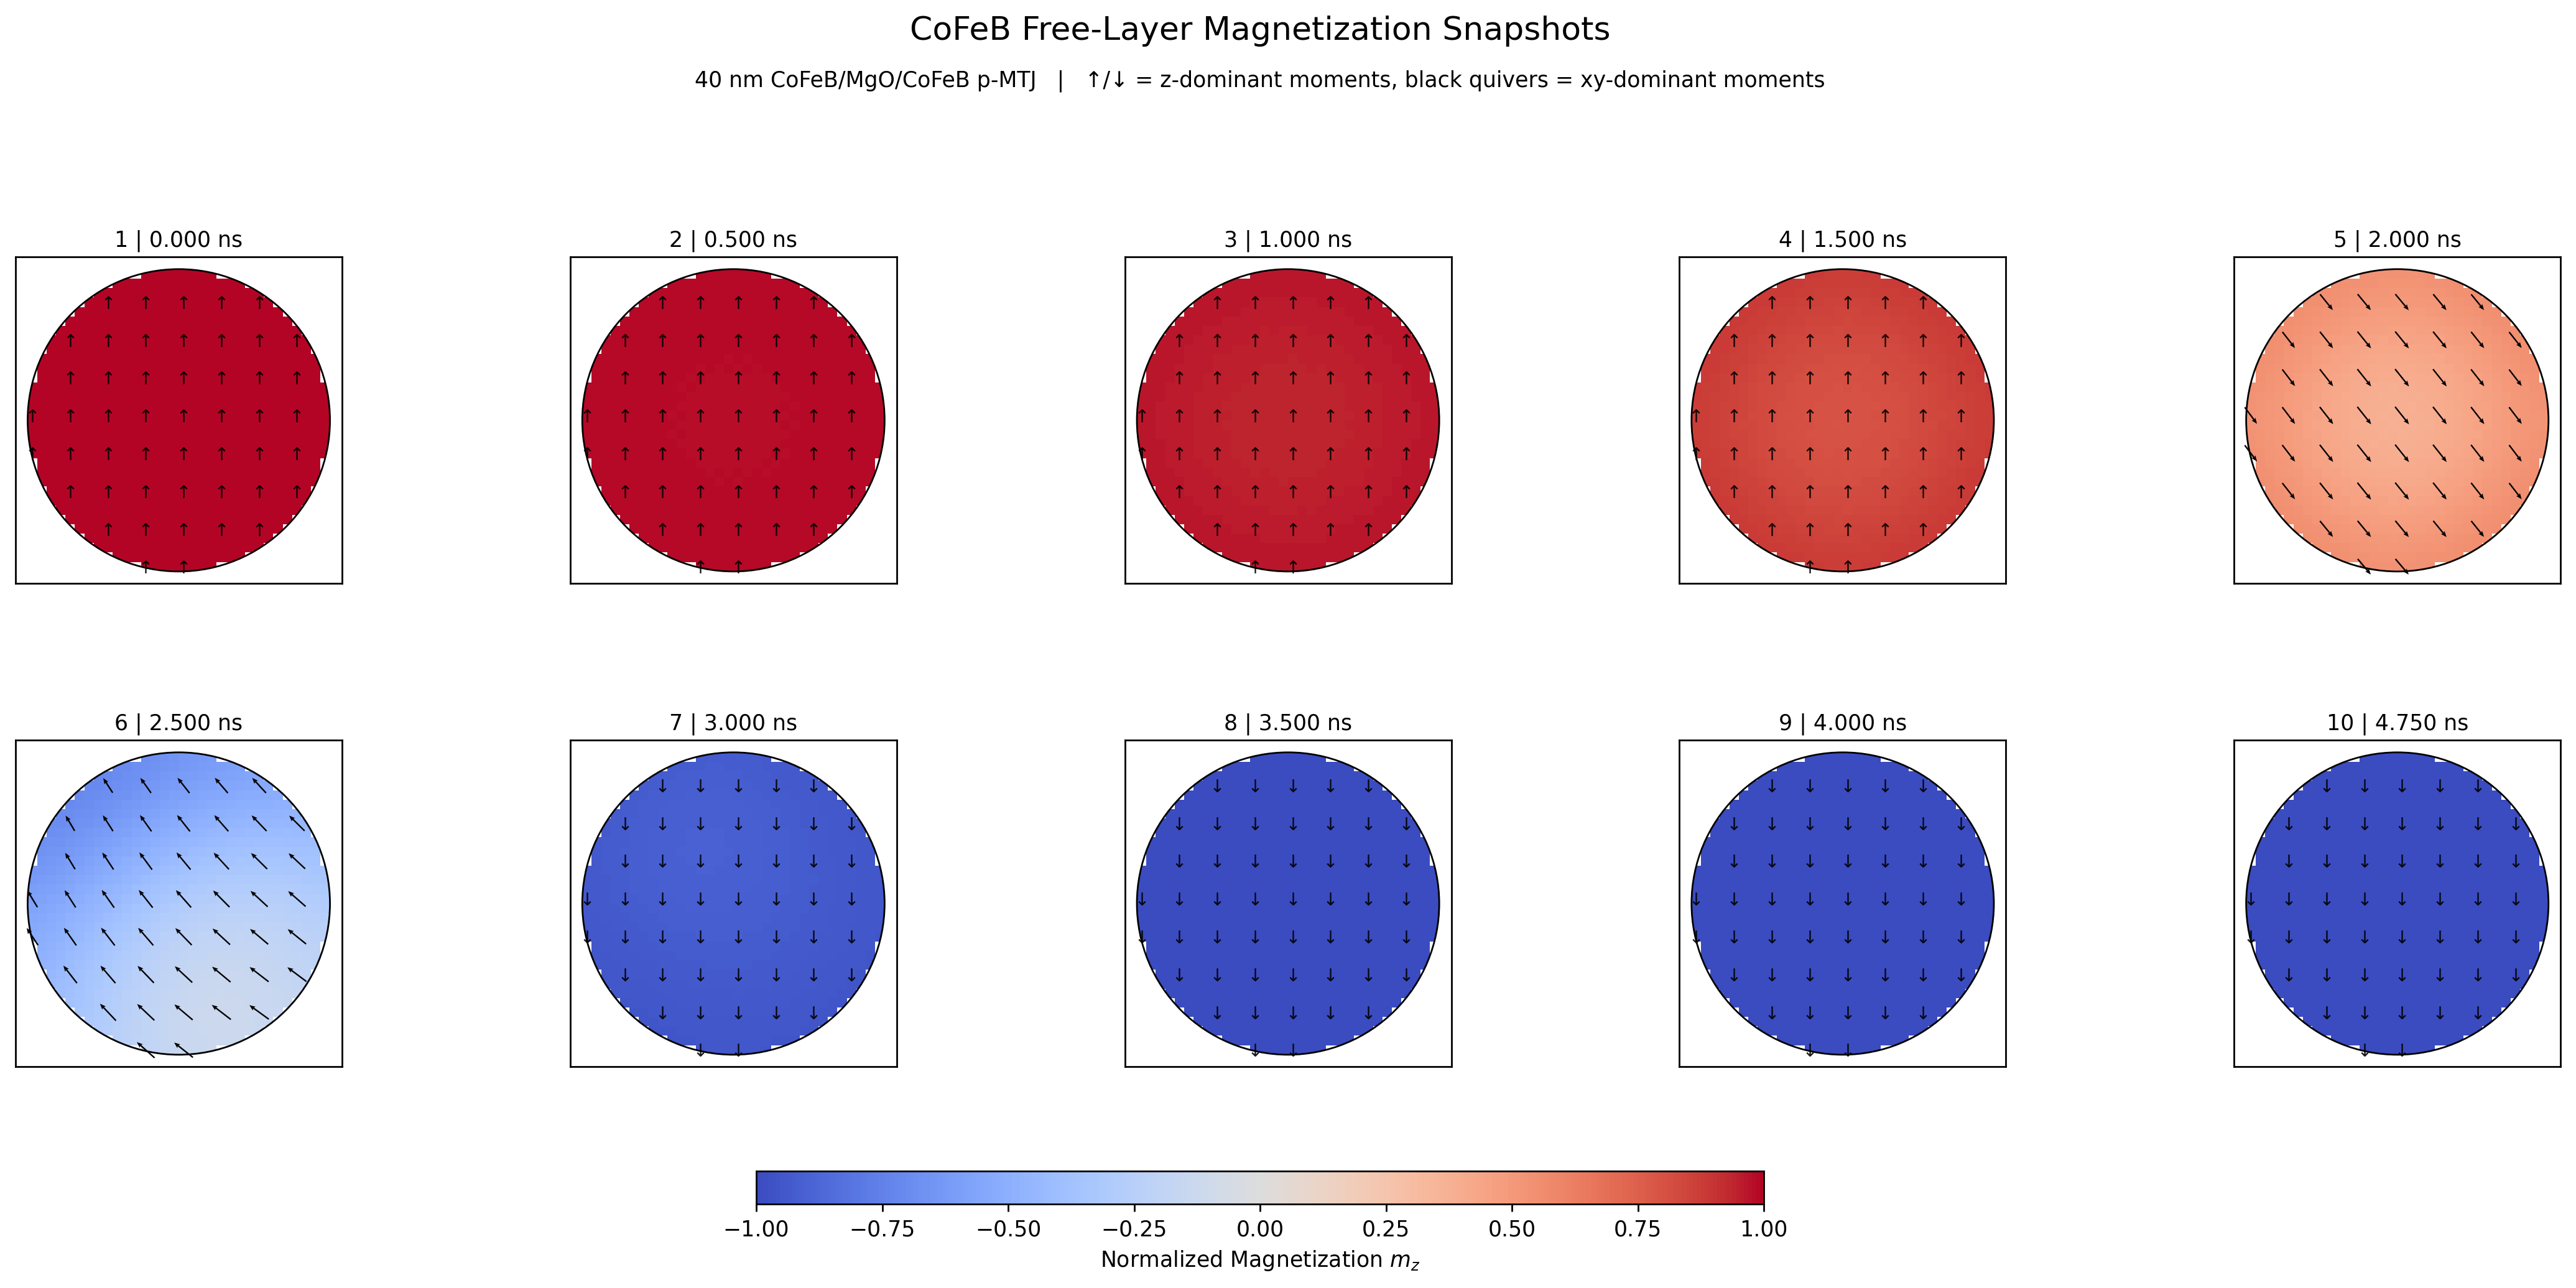


Final spatially averaged magnetization for Circular Free Layer
  mx=+0.000902 | my=-0.009012 | mz=-0.999958
  final free-layer state=AP
  first confirmed target-state entry=2.800022 ns
  final |mz| target criterion=0.800
  switching confirmed=True
  reference layer=CoFeB rigid polarizer along +z

Cell 1 complete.
Prepared 10 spatial snapshots for the K3D visualization in Cell 2.
MuMax3 GPU integration wall time: 93.026 s
Total Python-stage wall time: 112.157 s
For final numerical convergence, rerun with MUMAX_PERFORMANCE_PROFILE = "ACCURATE".
The FAST profile is intended to establish switching behavior and visualization before the 64 x 64 convergence run.


In [1]:
# ---------------------------------------------------
# Cell 1 - MuMax3 simulation
# ---------------------------------------------------

# Install the complete two-cell environment once.
!apt-get -qq update && apt-get -qq install -y openmpi-bin libopenmpi-dev
!uv pip install -q -U "numpy>=2.3.5,<2.4" "scipy>=1.16,<1.17" pandas mpi4py k3d cupy-cuda12x trimesh matplotlib rtree embreex ipywidgets

from google.colab import output
output.enable_custom_widget_manager()


"""Simulate a 40 nm single-interface perpendicular CoFeB/MgO/CoFeB MTJ.

The dynamic MuMax3 region represents the CoFeB recording/free layer. Meanwhile,
the CoFeB reference layer is represented by MuMax3's rigid ``fixedlayer`` spin
polarizer. Device dimensions and measured device-level targets follow a
single-interface 40 nm p-MTJ. The micromagnetic exchange and
saturation-magnetization constants are supplemental model parameters.
"""

# ---------------------------------------------------
# Standard Library Imports
# ---------------------------------------------------

import glob
import os
import re
import shutil
import subprocess
import threading
import time
from collections.abc import Sequence
from pathlib import Path

# ---------------------------------------------------
# Scientific Imports
# ---------------------------------------------------

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize
from matplotlib.patches import Circle, Ellipse, Patch, Rectangle

# ---------------------------------------------------
# Control Knobs - MuMax3 Environment
# ---------------------------------------------------

MUMAX_URL = (
    "https://mumax.ugent.be/"
    "mumax3-binaries/mumax3.12_linux_cuda12.9.tar.gz"
)
ARCHIVE_NAME = "mumax3.12_linux_cuda12.9.tar.gz"
EXTRACTED_DIR = "mumax3.12_linux_cuda12.9"
TARGET_DIR = "mumax3.12"

SIMULATION_FILENAME = "stt_bit_cell.mx3"
RESULTS_DIRECTORY = "stt_bit_cell.out"
TABULAR_DATA_FILE = "table.txt"
CLEAN_PREVIOUS_RESULTS = True


'''Single-interface CoFeB-MgO p-MTJ baseline.

<https://doi.org/10.1109/IEDM.2014.7047160>

An example paper reports the following 40 nm device stack and metrics:
    Si/SiO2 / Ta(5) / Ru(10) / Ta(5) / CoFeB(1.0) /
    MgO(0.85) / CoFeB(1.7) / Ta(5) / Ru(5) / Cr/Au

Thicknesses above are in nanometers. The 40 nm device is reported after a
300 degC anneal with TMR = 124%, intrinsic critical current Ic0 = 49 uA,
and thermal stability factor Delta = 43.

The dynamic MuMax3 body is the 1.7 nm CoFeB recording/free layer. The
1.0 nm CoFeB reference layer is treated as a rigid perpendicular polarizer.
MgO and the metallic seed/cap layers are recorded as stack metadata rather
than magnetic MuMax3 regions.

Python reserves the lowercase word `lambda`, so the Python control knob is
written as ``Lambda``. MuMax3 input syntax is case independent; the generated
script uses the API's canonical built-in names ``Lambda``, ``EpsilonPrime``,
and ``FixedLayer``.
'''

# ---------------------------------------------------
# Control Knobs - SI Units
# ---------------------------------------------------

# Single-interface CoFeB/MgO/CoFeB perpendicular MTJ.
FREE_LAYER_MATERIAL = "CoFeB"
REFERENCE_LAYER_MATERIAL = "CoFeB"
TUNNEL_BARRIER_MATERIAL = "MgO"

PILLAR_DIAMETER_M = 40e-9
FREE_LAYER_THICKNESS_M = 1.7e-9
MGO_BARRIER_THICKNESS_M = 0.85e-9
REFERENCE_LAYER_THICKNESS_M = 1.0e-9

# Paper-reported 40 nm device targets.
PAPER_ANNEAL_TEMPERATURE_C = 300.0
PAPER_TMR_RATIO_FRACTION = 1.24
PAPER_INTRINSIC_CRITICAL_CURRENT_A = 49e-6
PAPER_THERMAL_STABILITY_FACTOR = 43.0

# Fundamental constants used for device-level calibration.
BOLTZMANN_J_PER_K = 1.380649e-23
VACUUM_PERMEABILITY_H_PER_M = 4.0 * np.pi * 1.0e-7
REDUCED_PLANCK_J_S = 1.054571817e-34
ELEMENTARY_CHARGE_C = 1.602176634e-19
GYROMAGNETIC_RATIO_RAD_PER_T_S = 1.7595e11

# Simulation box and dynamic free-layer geometry.
sizeX = PILLAR_DIAMETER_M
sizeY = PILLAR_DIAMETER_M
sizeZ = FREE_LAYER_THICKNESS_M

# The 64 x 64 in-plane grid gives 0.625 nm cells for a 40 nm pillar.
Nx = 64
Ny = 64
Nz = 1

# MuMax3 geometry expression inserted directly into setGeom(...).
#
# Supported geometry options:
#     "circle(sizeX)"                    # 2D circle; sizeX is the diameter.
#     "ellipse(sizeX, sizeY)"            # 2D ellipse; x and y diameters.
#     "rect(sizeX, sizeY)"               # 2D rectangle.
#     "square(sizeX)"                    # 2D square.
#     "cylinder(sizeX, sizeZ)"           # 3D cylinder; diameter and height.
#     "cuboid(sizeX, sizeY, sizeZ)"      # 3D cuboid.
#     "ellipsoid(sizeX, sizeY, sizeZ)"   # 3D ellipsoid.
#
# The paper-matched p-MTJ is a circular 40 nm pillar.
GEOMETRY_EXPRESSION = "circle(sizeX)"

# MuMax3 subcell edge smoothing reduces staircase artifacts at the circular
# pillar boundary. The official MuMax3 geometry example uses values such as 8.
EDGE_SMOOTH_SAMPLES = 8


# ---------------------------------------------------
# CoFeB Micromagnetic Material Calibration
# ---------------------------------------------------

# The paper does not tabulate Ms or Aex for the exact 40 nm single-interface
# device. These stay exposed as supplemental CoFeB micromagnetic controls.
Msat = 1.0e6
Aex = 20e-12

PAPER_FREE_LAYER_AREA_M2 = (
    np.pi
    * (0.5 * PILLAR_DIAMETER_M) ** 2
)
PAPER_FREE_LAYER_VOLUME_M3 = (
    PAPER_FREE_LAYER_AREA_M2
    * FREE_LAYER_THICKNESS_M
)

# The measured Delta fixes the room-temperature effective energy barrier.
ANISOTROPY_CALIBRATION_TEMPERATURE_K = 300.0
PAPER_ANISOTROPY_BARRIER_J = (
    PAPER_THERMAL_STABILITY_FACTOR
    * BOLTZMANN_J_PER_K
    * ANISOTROPY_CALIBRATION_TEMPERATURE_K
)

Keff_target = (
    PAPER_ANISOTROPY_BARRIER_J
    / PAPER_FREE_LAYER_VOLUME_M3
)

# Infer an effective symmetric-electrode polarization from TMR using the
# Julliere relation. This is an STT model parameter, not a direct measurement.
Pol = np.sqrt(
    PAPER_TMR_RATIO_FRACTION
    / (
        PAPER_TMR_RATIO_FRACTION
        + 2.0
    )
)

# The paper's scaling analysis compares alpha = 0.008, 0.012, and 0.016.
# Use the middle value as a representative CoFeB device-level damping
# parameter. The measured Ic0 remains an experimental reference rather than
# being used to force alpha to a macrospin threshold fit.
alpha = 0.012

# MuMax3 calculates demagnetization explicitly. Ku1 adds the thin-film
# demagnetization estimate to the Delta-derived effective anisotropy.
thin_film_demag_energy_density = (
    0.5
    * VACUUM_PERMEABILITY_H_PER_M
    * Msat**2
)

Ku1 = (
    Keff_target
    + thin_film_demag_energy_density
)

# Perpendicular easy axis.
anisU = (0.0, 0.0, 1.0)

INTERFACE_ANISOTROPY_J_PER_M2 = (
    Ku1
    * FREE_LAYER_THICKNESS_M
)

# Reference-layer metadata. Its dynamics are represented by MuMax3's rigid
# Slonczewski fixed-layer polarization.
REFERENCE_MSAT_A_PER_M = Msat
REFERENCE_AEX_J_PER_M = Aex
REFERENCE_ALPHA = alpha
REFERENCE_KU1_J_PER_M3 = (
    INTERFACE_ANISOTROPY_J_PER_M2
    / REFERENCE_LAYER_THICKNESS_M
)
REFERENCE_ANISOTROPY_AXIS = (0.0, 0.0, 1.0)


# ---------------------------------------------------
# Switching Target and Initial State
# ---------------------------------------------------

# Accepted:
#     "P_TO_AP"    Start parallel to the reference layer and write AP.
#     "AP_TO_P"    Start antiparallel and write P.
SWITCH_TARGET = "P_TO_AP"

# A finite deterministic canting angle stands in for the thermal
# fluctuation that seeds switching in a room-temperature device.
INITIAL_TILT_DEG = 5.0
SWITCH_CONFIRMATION_THRESHOLD_MZ = 0.80
# "WARN" preserves plots and Cell 2 input after an incomplete write.
# "ERROR" is useful for automated regression runs.
SWITCH_FAILURE_POLICY = "WARN"

if SWITCH_TARGET == "P_TO_AP":
    INITIAL_FREE_LAYER_STATE = "P"
    initial_z_sign = 1.0
    target_z_sign = -1.0

    # The reference layer is physically below the free layer. MuMax3 reverses
    # the Slonczewski current sign internally for FIXEDLAYER_BOTTOM, so +Jz
    # destabilizes the P state for this convention.
    CURRENT_DIRECTION_SIGN = 1.0
elif SWITCH_TARGET == "AP_TO_P":
    INITIAL_FREE_LAYER_STATE = "AP"
    initial_z_sign = -1.0
    target_z_sign = 1.0
    CURRENT_DIRECTION_SIGN = -1.0
else:
    raise ValueError(
        "SWITCH_TARGET must be 'P_TO_AP' or 'AP_TO_P'."
    )

initial_tilt_rad = np.deg2rad(
    INITIAL_TILT_DEG
)

m = (
    float(np.sin(initial_tilt_rad)),
    0.0,
    float(
        initial_z_sign
        * np.cos(initial_tilt_rad)
    ),
)

# CoFeB reference layer is perpendicular and points along +z.
reference_m = (0.0, 0.0, 1.0)


# ---------------------------------------------------
# Slonczewski Spin-Transfer-Torque Parameters
# ---------------------------------------------------

Lambda = 1.0
epsilonprime = 0.0
DisableZhangLiTorque = True


# ---------------------------------------------------
# Write Pulse
# ---------------------------------------------------

# Ic0 is a threshold current. A finite-time write pulse should exceed Ic0.
# The default applies 2.5 Ic0, giving 122.5 uA for the 40 nm paper device.
CURRENT_OVERDRIVE_FACTOR = 2.5

if CURRENT_OVERDRIVE_FACTOR <= 1.0:
    raise ValueError(
        "CURRENT_OVERDRIVE_FACTOR must exceed 1 for a deterministic "
        "finite-time switching attempt."
    )

CURRENT_SPECIFICATION = "TOTAL_CURRENT"

Jtot = (
    CURRENT_DIRECTION_SIGN
    * CURRENT_OVERDRIVE_FACTOR
    * PAPER_INTRINSIC_CRITICAL_CURRENT_A
)

jc = None

# Apply STT for the pulse, then remove current and verify that the free layer
# settles into the target perpendicular state.
WRITE_PULSE_DURATION_S = 4e-9
POST_PULSE_SETTLING_TIME_S = 1e-9
run_time = (
    WRITE_PULSE_DURATION_S
    + POST_PULSE_SETTLING_TIME_S
)


# ---------------------------------------------------
# MuMax3 Performance Profile
# ---------------------------------------------------

# "FAST" is intended for interactive Google Colab work.
# "ACCURATE" restores the denser output and MuMax3 default MaxErr for a
# final convergence check. Device physics and pulse duration stay unchanged.
MUMAX_PERFORMANCE_PROFILE = "FAST"

MUMAX_SOLVER_TYPE = 5
MUMAX_PROGRESS_HEARTBEAT_S = 15.0
MUMAX_LONG_RUN_WARNING_S = 60.0
PRINT_GENERATED_MX3 = False

if MUMAX_PERFORMANCE_PROFILE == "FAST":
    # 1.25 nm cells remain well below the approximately 5.6 nm exchange
    # length. Relative to 64 x 64, this also relaxes the high-k exchange
    # stiffness that can drive explicit adaptive timesteps very small.
    Nx = 32
    Ny = 32
    Nz = 1
    EDGE_SMOOTH_SAMPLES = 4

    MUMAX_MAX_ERROR = 2.0e-4
    autosave_m = 250e-12
    tableautosave_dt = 10e-12
    SAVE_ENERGY_TERMS = False
elif MUMAX_PERFORMANCE_PROFILE == "ACCURATE":
    Nx = 64
    Ny = 64
    Nz = 1
    EDGE_SMOOTH_SAMPLES = 8

    MUMAX_MAX_ERROR = 1.0e-5
    autosave_m = 50e-12
    tableautosave_dt = 5e-12
    SAVE_ENERGY_TERMS = True
else:
    raise ValueError(
        "MUMAX_PERFORMANCE_PROFILE must be 'FAST' or 'ACCURATE'."
    )

EXPECTED_OVF_OUTPUT_COUNT = int(
    np.ceil(run_time / autosave_m)
)
EXPECTED_TABLE_OUTPUT_COUNT = int(
    np.ceil(run_time / tableautosave_dt)
)

# Electrical pulse energy requires resistance or RA. The uploaded paper text
# describes RA comparisons without supplying a numerical RA for this exact
# 40 nm single-interface device. Set a measured RA here if available.
RESISTANCE_AREA_PRODUCT_OHM_UM2 = None


# ---------------------------------------------------
# Derived Compatibility Values - Do Not Edit
# ---------------------------------------------------

# Cell 2 uses nanometers for K3D geometry. These aliases preserve the existing
# two-cell interface while the actual simulation knobs stay in MuMax3 SI units.
SIZE_X_NM = sizeX * 1e9
SIZE_Y_NM = sizeY * 1e9
SIZE_Z_NM = sizeZ * 1e9

GRID_NX = Nx
GRID_NY = Ny
GRID_NZ = Nz

MSAT_A_PER_M = Msat
EXCHANGE_STIFFNESS_J_PER_M = Aex
GILBERT_DAMPING = alpha

INITIAL_MX = float(m[0])
INITIAL_MY = float(m[1])
INITIAL_MZ = float(m[2])

SLONCZEWSKI_LAMBDA = Lambda
POLARIZATION = Pol
EPSILON_PRIME = epsilonprime
REFERENCE_MX = float(reference_m[0])
REFERENCE_MY = float(reference_m[1])
REFERENCE_MZ = float(reference_m[2])

UNIAXIAL_ANISOTROPY_J_PER_M3 = Ku1
ANISOTROPY_AXIS_X = float(anisU[0])
ANISOTROPY_AXIS_Y = float(anisU[1])
ANISOTROPY_AXIS_Z = float(anisU[2])
TOTAL_CURRENT_A = Jtot
WRITE_CURRENT_OVERDRIVE = CURRENT_OVERDRIVE_FACTOR
WRITE_PULSE_DURATION = WRITE_PULSE_DURATION_S
POST_PULSE_SETTLING_TIME = POST_PULSE_SETTLING_TIME_S
TARGET_MZ_SIGN = target_z_sign

MAGNETIZATION_AUTOSAVE_S = autosave_m
TABLE_AUTOSAVE_S = tableautosave_dt
TOTAL_SIMULATION_TIME_S = run_time

MUMAX_ADAPTIVE_MAX_ERROR = MUMAX_MAX_ERROR
MUMAX_SELECTED_SOLVER = MUMAX_SOLVER_TYPE
MUMAX_ENERGY_LOGGING_ENABLED = SAVE_ENERGY_TERMS


# ---------------------------------------------------
# Control Knobs - Matplotlib
# ---------------------------------------------------

FIGURE_RESOLUTION_DPI = 250
FONT_FAMILY_PREFERENCE = ["Tahoma", "DejaVu Sans"]
FONT_WEIGHT_PREFERENCE = "normal"

SNAPSHOT_ROWS = 2
SNAPSHOT_COLUMNS = 5
MAX_SNAPSHOTS = 10

# Snapshot-vector rendering controls.
#
# Each sampled magnetic moment is assigned exactly one visible glyph:
#
#     z-dominant moment       -> upward/downward out-of-plane symbol
#     transverse-dominant     -> xy quiver arrow
#
# This avoids superimposing two arrow glyphs at the same cell. Transverse
# arrows retain their projected magnitude instead of being normalized to an
# identical length, so a small canting angle stays visually small.
QUIVER_SUBSAMPLING_STEP = 4

QUIVER_MAX_ARROW_LENGTH_NM = 3.2
QUIVER_SHAFT_WIDTH = 0.0045
QUIVER_HEAD_WIDTH = 3.2
QUIVER_HEAD_LENGTH = 4.0
QUIVER_HEAD_AXIS_LENGTH = 3.5

MAGNETIZATION_MINIMUM_MAGNITUDE = 1.0e-6
TRANSVERSE_QUIVER_MINIMUM_MAGNITUDE = 0.18

OUT_OF_PLANE_DOMINANCE_THRESHOLD_MZ = 0.72
OUT_OF_PLANE_ARROW_MARKER_SIZE = 36.0
OUT_OF_PLANE_ARROW_ALPHA = 0.90

CLIP_SCALAR_FIELD_TO_GEOMETRY = True

# Draw the physical free-layer perimeter over each vector snapshot.
DRAW_GEOMETRY_OUTLINE = True
GEOMETRY_OUTLINE_LINE_WIDTH = 0.8

MAGNETIZATION_COLOR_DIRECTION = "M_Z"
# Accepted: "M_X", "M_Y", "M_Z", "MAGNITUDE"

COLOR_MIN = -1.0
COLOR_MAX = 1.0


# ---------------------------------------------------
# Matplotlib Configuration
# ---------------------------------------------------

plt.rcParams["figure.dpi"] = FIGURE_RESOLUTION_DPI
plt.rcParams["font.sans-serif"] = FONT_FAMILY_PREFERENCE
plt.rcParams["font.weight"] = FONT_WEIGHT_PREFERENCE


# ---------------------------------------------------
# Runtime Diagnostics
# ---------------------------------------------------

CELL_1_PYTHON_START_TIME = time.perf_counter()


def run_streaming_process(
    command: Sequence[str],
    label: str,
    heartbeat_s: float = MUMAX_PROGRESS_HEARTBEAT_S,
) -> tuple[int, str, float]:
    """Run a subprocess with live output and elapsed-time heartbeats."""
    start_time = time.perf_counter()

    process = subprocess.Popen(
        list(command),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    if process.stdout is None:
        raise RuntimeError(
            f"{label} did not expose a readable stdout stream."
        )

    output_lines: list[str] = []

    def consume_output() -> None:
        """Stream subprocess output without losing it for error reporting."""
        if process.stdout is None:
            return

        for line in process.stdout:
            output_lines.append(line)
            print(line, end="", flush=True)

    output_thread = threading.Thread(
        target=consume_output,
        name=f"{label}-stdout",
        daemon=True,
    )
    output_thread.start()

    next_heartbeat = heartbeat_s
    long_run_reported = False

    while process.poll() is None:
        time.sleep(0.5)
        elapsed_s = time.perf_counter() - start_time

        if heartbeat_s > 0.0 and elapsed_s >= next_heartbeat:
            print(
                f"[{label}] elapsed {elapsed_s:.1f} s ...",
                flush=True,
            )
            next_heartbeat += heartbeat_s

        if (
            not long_run_reported
            and elapsed_s >= MUMAX_LONG_RUN_WARNING_S
        ):
            print(
                f"[{label}] exceeded "
                f"{MUMAX_LONG_RUN_WARNING_S:.0f} s and is still alive.",
                flush=True,
            )
            long_run_reported = True

    output_thread.join()

    elapsed_s = time.perf_counter() - start_time

    return (
        int(process.returncode),
        "".join(output_lines),
        elapsed_s,
    )


# ---------------------------------------------------
# Utility Functions Shared with Cell 2
# ---------------------------------------------------

def select_evenly_spaced_files(
    file_paths: Sequence[str],
    maximum_count: int,
) -> list[str]:
    """Select approximately uniform snapshots from an ordered file sequence."""
    file_paths = list(file_paths)

    if len(file_paths) <= maximum_count:
        return file_paths

    indices = np.linspace(
        0,
        len(file_paths) - 1,
        maximum_count,
        dtype=int,
    )
    return [file_paths[index] for index in indices]


def read_ovf_time_seconds(
    ovf_path: str | Path,
) -> float | None:
    """Extract physical simulation time from a MuMax3 OVF header."""
    patterns = (
        re.compile(
            r"Total simulation time:\s*"
            r"([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)"
        ),
        re.compile(
            r"Time \(s\):\s*"
            r"([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)"
        ),
    )

    with open(ovf_path, "rb") as file:
        for _ in range(300):
            raw_line = file.readline()

            if raw_line == b"":
                break

            line = raw_line.decode(
                "utf-8",
                errors="ignore",
            ).strip()

            for pattern in patterns:
                match = pattern.search(line)

                if match:
                    return float(match.group(1))

            if "Begin: Data" in line:
                break

    return None


def ensure_vector_array_shape(
    vector_data: np.ndarray,
) -> np.ndarray:
    """Return MuMax3 vector data with shape (3, Nz, Ny, Nx)."""
    vector_data = np.asarray(vector_data)

    if vector_data.ndim == 4 and vector_data.shape[0] == 3:
        return vector_data

    if vector_data.ndim == 3 and vector_data.shape[0] == 3:
        return vector_data[:, np.newaxis, :, :]

    raise ValueError(
        "Unexpected MuMax3 NumPy field shape: "
        f"{vector_data.shape}. Expected (3, Nz, Ny, Nx)."
    )


def get_scalar_field(
    vector_data: np.ndarray,
    component_name: str,
) -> np.ndarray:
    """Return the scalar field used for color mapping."""
    mx_grid = vector_data[0]
    my_grid = vector_data[1]
    mz_grid = vector_data[2]

    if component_name == "M_X":
        return mx_grid
    if component_name == "M_Y":
        return my_grid
    if component_name == "M_Z":
        return mz_grid
    if component_name == "MAGNITUDE":
        return np.sqrt(
            mx_grid**2
            + my_grid**2
            + mz_grid**2
        )

    raise ValueError(
        "MAGNETIZATION_COLOR_DIRECTION must be "
        "'M_X', 'M_Y', 'M_Z', or 'MAGNITUDE'."
    )


def get_colorbar_label(
    component_name: str,
) -> str:
    """Return the mathematical label associated with the color quantity."""
    labels = {
        "M_X": r"Normalized Magnetization $m_x$",
        "M_Y": r"Normalized Magnetization $m_y$",
        "M_Z": r"Normalized Magnetization $m_z$",
        "MAGNITUDE": r"Magnetization Magnitude $|\mathbf{m}|$",
    }
    return labels[component_name]


def get_color_range(
    component_name: str,
) -> tuple[float, float]:
    """Return the plotting range for the chosen scalar quantity."""
    if component_name == "MAGNITUDE":
        return 0.0, 1.0

    return COLOR_MIN, COLOR_MAX


# ---------------------------------------------------
# Geometry Interpretation and Matplotlib Projection
# ---------------------------------------------------

SUPPORTED_GEOMETRY_TYPES = {
    "circle",
    "ellipse",
    "rect",
    "square",
    "cylinder",
    "cuboid",
    "ellipsoid",
}

GEOMETRY_DISPLAY_NAMES = {
    "circle": "Circular Free Layer",
    "ellipse": "Elliptical Free Layer",
    "rect": "Rectangular Free Layer",
    "square": "Square Free Layer",
    "cylinder": "Cylindrical Free Layer",
    "cuboid": "Cuboid Free Layer",
    "ellipsoid": "Ellipsoidal Free Layer",
}


def get_geometry_type(
    geometry_expression: str,
) -> str:
    """Return the MuMax3 shape name from a geometry expression."""
    match = re.fullmatch(
        r"\s*([A-Za-z_][A-Za-z0-9_]*)\s*\(.*\)\s*",
        geometry_expression,
    )

    if match is None:
        raise ValueError(
            "GEOMETRY_EXPRESSION must use the form "
            "'shape(arguments)', for example 'circle(sizeX)'."
        )

    geometry_type = match.group(1).lower()

    if geometry_type not in SUPPORTED_GEOMETRY_TYPES:
        supported_text = ", ".join(
            sorted(SUPPORTED_GEOMETRY_TYPES)
        )
        raise ValueError(
            f"Unsupported geometry '{geometry_type}'. "
            f"Supported geometries: {supported_text}."
        )

    return geometry_type


def get_geometry_cross_section_area_m2(
    geometry_type: str,
    size_x_m: float,
    size_y_m: float,
) -> float:
    """Return the xy cross-sectional area used for current density."""
    if geometry_type in {"circle", "cylinder"}:
        return np.pi * (0.5 * size_x_m) ** 2

    if geometry_type in {"ellipse", "ellipsoid"}:
        return np.pi * size_x_m * size_y_m / 4.0

    if geometry_type in {"rect", "cuboid"}:
        return size_x_m * size_y_m

    if geometry_type == "square":
        return size_x_m**2

    raise ValueError(
        f"Cross-sectional area is undefined for '{geometry_type}'."
    )


def create_geometry_outline_patch(
    geometry_type: str,
    size_x_nm: float,
    size_y_nm: float,
    line_width: float,
) -> Patch:
    """Create the Matplotlib xy projection of the selected MuMax3 shape."""
    common_kwargs = {
        "fill": False,
        "linewidth": line_width,
    }

    if geometry_type in {"circle", "cylinder"}:
        return Circle(
            (0.0, 0.0),
            radius=0.5 * size_x_nm,
            **common_kwargs,
        )

    if geometry_type in {"ellipse", "ellipsoid"}:
        return Ellipse(
            (0.0, 0.0),
            width=size_x_nm,
            height=size_y_nm,
            **common_kwargs,
        )

    if geometry_type in {"rect", "cuboid"}:
        return Rectangle(
            (-0.5 * size_x_nm, -0.5 * size_y_nm),
            width=size_x_nm,
            height=size_y_nm,
            **common_kwargs,
        )

    if geometry_type == "square":
        return Rectangle(
            (-0.5 * size_x_nm, -0.5 * size_x_nm),
            width=size_x_nm,
            height=size_x_nm,
            **common_kwargs,
        )

    raise ValueError(
        f"Matplotlib projection is undefined for '{geometry_type}'."
    )


def get_geometry_plot_extents_nm(
    geometry_type: str,
    size_x_nm: float,
    size_y_nm: float,
) -> tuple[float, float]:
    """Return symmetric xy half-extents for the selected shape."""
    if geometry_type in {"circle", "cylinder", "square"}:
        half_x_nm = 0.5 * size_x_nm
        half_y_nm = 0.5 * size_x_nm
        return half_x_nm, half_y_nm

    half_x_nm = 0.5 * size_x_nm
    half_y_nm = 0.5 * size_y_nm
    return half_x_nm, half_y_nm


def get_geometry_point_mask(
    x_coordinates_nm: np.ndarray,
    y_coordinates_nm: np.ndarray,
    geometry_type: str,
    size_x_nm: float,
    size_y_nm: float,
) -> np.ndarray:
    """Return a Boolean mask for points inside the selected xy footprint."""
    if geometry_type in {"circle", "cylinder"}:
        radius_nm = 0.5 * size_x_nm
        return (
            x_coordinates_nm**2
            + y_coordinates_nm**2
            <= radius_nm**2
        )

    if geometry_type in {"ellipse", "ellipsoid"}:
        radius_x_nm = 0.5 * size_x_nm
        radius_y_nm = 0.5 * size_y_nm

        return (
            (x_coordinates_nm / radius_x_nm) ** 2
            + (y_coordinates_nm / radius_y_nm) ** 2
            <= 1.0
        )

    if geometry_type == "square":
        half_width_nm = 0.5 * size_x_nm
        return (
            (np.abs(x_coordinates_nm) <= half_width_nm)
            & (np.abs(y_coordinates_nm) <= half_width_nm)
        )

    if geometry_type in {"rect", "cuboid"}:
        half_x_nm = 0.5 * size_x_nm
        half_y_nm = 0.5 * size_y_nm

        return (
            (np.abs(x_coordinates_nm) <= half_x_nm)
            & (np.abs(y_coordinates_nm) <= half_y_nm)
        )

    raise ValueError(
        f"Geometry mask is undefined for '{geometry_type}'."
    )


# ---------------------------------------------------
# Geometry and Mesh Preflight
# ---------------------------------------------------

GEOMETRY_TYPE = get_geometry_type(
    GEOMETRY_EXPRESSION
)
GEOMETRY_DISPLAY_NAME = GEOMETRY_DISPLAY_NAMES[
    GEOMETRY_TYPE
]

cell_size_x_m = sizeX / Nx
cell_size_y_m = sizeY / Ny

if min(sizeX, sizeY, sizeZ) <= 0.0:
    raise ValueError(
        "sizeX, sizeY, and sizeZ must all be positive."
    )

if min(Nx, Ny, Nz) <= 0:
    raise ValueError(
        "Nx, Ny, and Nz must all be positive integers."
    )

if GEOMETRY_TYPE in {"circle", "cylinder", "square"}:
    if sizeY + 1.0e-18 < sizeX:
        raise ValueError(
            f"{GEOMETRY_TYPE} uses sizeX as its in-plane diameter or "
            "width, so sizeY must be at least sizeX."
        )

GEOMETRY_AREA_M2 = get_geometry_cross_section_area_m2(
    GEOMETRY_TYPE,
    sizeX,
    sizeY,
)

print("Geometry interpretation")
print(
    f"  MuMax3 expression: {GEOMETRY_EXPRESSION}"
)
print(
    f"  Matplotlib projection: {GEOMETRY_DISPLAY_NAME}"
)
print(
    f"  box: {sizeX * 1.0e9:.3f} x "
    f"{sizeY * 1.0e9:.3f} x "
    f"{sizeZ * 1.0e9:.3f} nm"
)
print(
    f"  mesh cell: {cell_size_x_m * 1.0e9:.3f} x "
    f"{cell_size_y_m * 1.0e9:.3f} nm in plane"
)
print(
    f"  current cross section: "
    f"{GEOMETRY_AREA_M2 * 1.0e18:.6f} nm^2"
)

exchange_length_m = np.sqrt(
    2.0
    * Aex
    / (
        VACUUM_PERMEABILITY_H_PER_M
        * Msat**2
    )
)

if max(cell_size_x_m, cell_size_y_m) > 0.75 * exchange_length_m:
    raise ValueError(
        "The in-plane mesh is too coarse relative to the exchange length. "
        "Increase Nx and Ny."
    )

MODEL_MACROSPIN_IC0_A = (
    4.0
    * ELEMENTARY_CHARGE_C
    * alpha
    * Keff_target
    * PAPER_FREE_LAYER_VOLUME_M3
    / (
        REDUCED_PLANCK_J_S
        * Pol
    )
)

applied_current_a = (
    Jtot
    if CURRENT_SPECIFICATION == "TOTAL_CURRENT"
    else jc * GEOMETRY_AREA_M2
)

applied_overdrive_vs_model = (
    abs(applied_current_a)
    / MODEL_MACROSPIN_IC0_A
)

if applied_overdrive_vs_model <= 1.0:
    raise ValueError(
        "Applied current does not exceed the internally calibrated "
        "macrospin critical current."
    )

effective_anisotropy_field_t = (
    2.0
    * Keff_target
    / Msat
)

initial_tilt_for_estimate_rad = max(
    abs(initial_tilt_rad),
    np.deg2rad(0.1),
)

switching_time_estimate_s = (
    1.0
    / (
        alpha
        * GYROMAGNETIC_RATIO_RAD_PER_T_S
        * effective_anisotropy_field_t
    )
    * np.log(
        np.pi
        / (
            2.0
            * initial_tilt_for_estimate_rad
        )
    )
    / (
        applied_overdrive_vs_model
        - 1.0
    )
)

if CURRENT_SPECIFICATION == "TOTAL_CURRENT":
    estimated_current_density = (
        Jtot
        / GEOMETRY_AREA_M2
    )
else:
    estimated_current_density = jc

print(
    f"  exchange length: "
    f"{exchange_length_m * 1.0e9:.6f} nm"
)
print(
    f"  applied current: "
    f"{applied_current_a * 1.0e6:+.6f} uA"
)
print(
    f"  applied current density: "
    f"{estimated_current_density / 1.0e10:+.6f} MA/cm^2"
)
print(
    f"  macrospin Ic0 consistency check: "
    f"{MODEL_MACROSPIN_IC0_A * 1.0e6:.6f} uA"
)
print(
    f"  current overdrive versus model Ic0: "
    f"{applied_overdrive_vs_model:.6f} x"
)
print(
    f"  approximate deterministic switching time: "
    f"{switching_time_estimate_s * 1.0e9:.6f} ns"
)
print(
    f"  write-pulse duration: "
    f"{WRITE_PULSE_DURATION_S * 1.0e9:.6f} ns"
)

if WRITE_PULSE_DURATION_S <= switching_time_estimate_s:
    print(
        "  warning: write pulse is shorter than the simple macrospin "
        "switching-time estimate."
    )

if RESISTANCE_AREA_PRODUCT_OHM_UM2 is None:
    print(
        "  electrical switching energy: unavailable until a measured "
        "RA product is supplied"
    )
else:
    area_um2 = GEOMETRY_AREA_M2 * 1.0e12
    parallel_resistance_ohm = (
        RESISTANCE_AREA_PRODUCT_OHM_UM2
        / area_um2
    )
    estimated_electrical_write_energy_j = (
        applied_current_a**2
        * parallel_resistance_ohm
        * WRITE_PULSE_DURATION_S
    )
    print(
        f"  estimated electrical write energy: "
        f"{estimated_electrical_write_energy_j:.6e} J"
    )

if not np.isclose(
    cell_size_x_m,
    cell_size_y_m,
    rtol=0.02,
    atol=0.0,
):
    print(
        "  mesh note: dx and dy differ. Matplotlib will still use "
        "physical nanometer coordinates, so the displayed geometry "
        "will preserve its physical aspect ratio."
    )


# ---------------------------------------------------
# GPU Verification
# ---------------------------------------------------

subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=name,driver_version,compute_cap",
        "--format=csv",
    ],
    check=True,
)


# ---------------------------------------------------
# MuMax3 Environment Preparation
# ---------------------------------------------------

target_path = Path(TARGET_DIR)

if not target_path.exists():
    archive_path = Path(ARCHIVE_NAME)
    extracted_path = Path(EXTRACTED_DIR)

    if archive_path.exists():
        archive_path.unlink()

    if extracted_path.exists():
        shutil.rmtree(extracted_path)

    subprocess.run(
        [
            "wget",
            "-q",
            "-O",
            ARCHIVE_NAME,
            MUMAX_URL,
        ],
        check=True,
    )

    subprocess.run(
        [
            "tar",
            "-xf",
            ARCHIVE_NAME,
        ],
        check=True,
    )

    Path(ARCHIVE_NAME).unlink()
    extracted_path.rename(target_path)

mumax_directory = str(target_path.resolve())
os.environ["PATH"] = (
    f"{mumax_directory}:"
    f"{os.environ['PATH']}"
)


# ---------------------------------------------------
# Clear Previous Simulation Output
# ---------------------------------------------------

if CLEAN_PREVIOUS_RESULTS and Path(RESULTS_DIRECTORY).exists():
    shutil.rmtree(RESULTS_DIRECTORY)


# ---------------------------------------------------
# MuMax3 Simulation Configuration
# ---------------------------------------------------

if len(m) != 3:
    raise ValueError("m must contain exactly three magnetization components.")

if CURRENT_SPECIFICATION == "TOTAL_CURRENT":
    current_configuration = f"""
Jtot := {Jtot}
area := {GEOMETRY_AREA_M2}
jc := Jtot / area
J = vector(0, 0, jc)
"""
elif CURRENT_SPECIFICATION == "CURRENT_DENSITY":
    if jc is None:
        raise ValueError(
            "Set jc in A/m^2 before using "
            'CURRENT_SPECIFICATION = "CURRENT_DENSITY".'
        )

    current_configuration = f"""
jc := {jc}
J = vector(0, 0, jc)
"""
else:
    raise ValueError(
        "CURRENT_SPECIFICATION must be "
        '"TOTAL_CURRENT" or "CURRENT_DENSITY".'
    )

disable_zhang_li_text = (
    "true"
    if DisableZhangLiTorque
    else "false"
)

if SAVE_ENERGY_TERMS:
    energy_table_configuration = """
// record internal micromagnetic energy terms
TableAdd(E_total)
TableAdd(E_anis)
TableAdd(E_demag)
TableAdd(E_exch)
TableAdd(dt)
""".strip()
else:
    energy_table_configuration = """
// lightweight timestep diagnostic for performance analysis
TableAdd(dt)
""".strip()

mx3_configuration = f"""
// geometry
sizeX := {sizeX}
sizeY := {sizeY}
sizeZ := {sizeZ}

Nx := {Nx}
Ny := {Ny}
Nz := {Nz}

SetGridSize(Nx, Ny, Nz)
SetCellSize(sizeX/Nx, sizeY/Ny, sizeZ/Nz)
EdgeSmooth = {EDGE_SMOOTH_SAMPLES}

// adaptive integration
SetSolver({MUMAX_SOLVER_TYPE})
MaxErr = {MUMAX_MAX_ERROR}

// GEOMETRY_EXPRESSION is inserted by Python as a MuMax3 Shape expression.
// Example generated line for the default control knob:
//     geometryShape := circle(sizeX)
geometryShape := {GEOMETRY_EXPRESSION}
SetGeom(geometryShape)

// set up CoFeB recording/free layer
Msat  = {Msat}
Aex   = {Aex}
alpha = {alpha}
Ku1   = {Ku1}
anisU = vector({anisU[0]}, {anisU[1]}, {anisU[2]})
m     = uniform({m[0]}, {m[1]}, {m[2]})

// set up spacer layer parameters
DisableZhangLiTorque = {disable_zhang_li_text}
Lambda       = {Lambda}
Pol          = {Pol}
EpsilonPrime = {epsilonprime}

// set up perpendicular CoFeB reference-layer polarization
// The physical stack places the reference CoFeB below MgO/free CoFeB.
FixedLayerPosition = FIXEDLAYER_BOTTOM
FreeLayerThickness = {FREE_LAYER_THICKNESS_M}
FixedLayer = vector({reference_m[0]}, {reference_m[1]}, {reference_m[2]})

// send current or switching current for STT MTJs
{current_configuration.strip()}

// schedule output
autosave(m, {autosave_m})
tableautosave({tableautosave_dt})

{energy_table_configuration}

// apply the finite STT write pulse
run({WRITE_PULSE_DURATION_S})

// remove write current and test nonvolatile settling
J = vector(0, 0, 0)
tablesave()
run({POST_PULSE_SETTLING_TIME_S})
"""

# ---------------------------------------------------
# Generated MuMax3 Script Sanity Checks
# ---------------------------------------------------

for forbidden_fragment in (
    'SetGeom("',
    "setGeom(\"",
    "FixedLayer :=",
    "fixedlayer :=",
):
    if forbidden_fragment in mx3_configuration:
        raise RuntimeError(
            "Generated MuMax3 input contains an invalid fragment: "
            f"{forbidden_fragment!r}"
        )

required_mx3_fragments = (
    f"geometryShape := {GEOMETRY_EXPRESSION}",
    "SetGeom(geometryShape)",
    "FixedLayerPosition = FIXEDLAYER_BOTTOM",
    "FreeLayerThickness =",
    "FixedLayer = vector(",
    "DisableZhangLiTorque = true",
)

missing_mx3_fragments = [
    fragment
    for fragment in required_mx3_fragments
    if fragment not in mx3_configuration
]

if missing_mx3_fragments:
    raise RuntimeError(
        "Generated MuMax3 input is missing required statements: "
        + ", ".join(missing_mx3_fragments)
    )

# MuMax3 uses a Go-like parser. Multi-line function argument lists can
# require a trailing comma before a newline. Keep the generated vector()
# assignments used by this notebook on one physical line to avoid that
# parser ambiguity.
for generated_line in mx3_configuration.splitlines():
    stripped_line = generated_line.strip()

    if stripped_line.startswith("FixedLayer = vector("):
        if not stripped_line.endswith(")"):
            raise RuntimeError(
                "FixedLayer vector assignment must remain on one "
                "generated MuMax3 line."
            )

# Reject the specific malformed pattern that previously caused:
# "missing ',' before newline in argument list".
if re.search(
    r"FixedLayer\s*=\s*vector\(\s*\n",
    mx3_configuration,
):
    raise RuntimeError(
        "Generated FixedLayer vector call spans multiple lines."
    )


def format_numbered_mx3(
    mx3_text: str,
) -> str:
    """Return a line-numbered MuMax3 input string for diagnostics."""
    return "\n".join(
        f"{line_number:04d}: {line}"
        for line_number, line in enumerate(
            mx3_text.splitlines(),
            start=1,
        )
    )


print("MuMax3 simulation controls")
print(
    f"  device: single-interface "
    f"{FREE_LAYER_MATERIAL}/{TUNNEL_BARRIER_MATERIAL}/"
    f"{REFERENCE_LAYER_MATERIAL} p-MTJ"
)
print(
    f"  geometry: {GEOMETRY_DISPLAY_NAME} | "
    f"D={PILLAR_DIAMETER_M * 1.0e9:.3f} nm | "
    f"grid={Nx} x {Ny} x {Nz}"
)
print(
    f"  layers: reference CoFeB="
    f"{REFERENCE_LAYER_THICKNESS_M * 1.0e9:.3f} nm | "
    f"MgO={MGO_BARRIER_THICKNESS_M * 1.0e9:.3f} nm | "
    f"free CoFeB={FREE_LAYER_THICKNESS_M * 1.0e9:.3f} nm"
)
print(
    f"  free layer: Msat={Msat:.6g} A/m | "
    f"Aex={Aex:.6g} J/m | alpha={alpha:.6g}"
)
print(
    f"  PMA: Ku1={Ku1:.6g} J/m^3 | "
    f"Keff target={Keff_target:.6g} J/m^3 | "
    f"Ki~={INTERFACE_ANISOTROPY_J_PER_M2 * 1.0e3:.6g} mJ/m^2"
)
print(
    f"  reference layer: rigid +z CoFeB polarizer | "
    f"nominal Ku1={REFERENCE_KU1_J_PER_M3:.6g} J/m^3"
)
print(
    f"  paper targets: TMR={PAPER_TMR_RATIO_FRACTION * 100.0:.1f}% | "
    f"Ic0={PAPER_INTRINSIC_CRITICAL_CURRENT_A * 1.0e6:.3f} uA | "
    f"Delta={PAPER_THERMAL_STABILITY_FACTOR:.1f}"
)
print(
    f"  STT: lambda={Lambda:.6g} | "
    f"effective Pol={Pol:.6g} | "
    f"epsilonprime={epsilonprime:.6g}"
)
print(
    f"  switch target: {SWITCH_TARGET} | "
    f"reference position=below free layer"
)
print(
    f"  current specification: {CURRENT_SPECIFICATION} | "
    f"overdrive={CURRENT_OVERDRIVE_FACTOR:.3f} x Ic0 | "
    f"Jtot={Jtot * 1.0e6:+.3f} uA"
)
print(
    f"  pulse={WRITE_PULSE_DURATION_S * 1.0e9:.3f} ns | "
    f"settle={POST_PULSE_SETTLING_TIME_S * 1.0e9:.3f} ns"
)
print(
    f"  performance profile: {MUMAX_PERFORMANCE_PROFILE} | "
    f"grid={Nx} x {Ny} x {Nz} | "
    f"solver={MUMAX_SOLVER_TYPE} | "
    f"MaxErr={MUMAX_MAX_ERROR:.1e}"
)
print(
    f"  expected output: ~{EXPECTED_OVF_OUTPUT_COUNT} OVF files | "
    f"~{EXPECTED_TABLE_OUTPUT_COUNT} table rows | "
    f"energy logging={SAVE_ENERGY_TERMS}"
)

with open(
    SIMULATION_FILENAME,
    "w",
    encoding="utf-8",
) as file:
    file.write(mx3_configuration)

if PRINT_GENERATED_MX3:
    print()
    print("Generated MuMax3 input")
    print(
        format_numbered_mx3(
            mx3_configuration
        )
    )
    print()


# ---------------------------------------------------
# MuMax3 Input Preflight
# ---------------------------------------------------

vet_start_time = time.perf_counter()

vet_result = subprocess.run(
    [
        "mumax3",
        "-http=",
        "-vet",
        SIMULATION_FILENAME,
    ],
    check=False,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)

vet_elapsed_s = time.perf_counter() - vet_start_time

if vet_result.stdout:
    print(vet_result.stdout)

print(
    f"MuMax3 -vet preflight wall time: {vet_elapsed_s:.3f} s"
)

if vet_result.returncode != 0:
    numbered_mx3 = format_numbered_mx3(
        mx3_configuration
    )

    raise RuntimeError(
        "MuMax3 rejected the generated input script during the -vet "
        f"preflight with exit code {vet_result.returncode}.\n\n"
        "MuMax3 preflight output:\n"
        f"{vet_result.stdout or '[no output]'}\n\n"
        "Generated MuMax3 input with line numbers:\n"
        f"{numbered_mx3}"
    )


# ---------------------------------------------------
# Numerical Execution
# ---------------------------------------------------

print()
print(
    "Starting MuMax3 GPU integration. "
    "Live output and elapsed time will appear below."
)

(
    mumax_returncode,
    mumax_stdout,
    mumax_elapsed_s,
) = run_streaming_process(
    [
        "mumax3",
        "-http=",
        SIMULATION_FILENAME,
    ],
    label="MuMax3",
)

print(
    f"MuMax3 numerical wall time: {mumax_elapsed_s:.3f} s"
)

if mumax_returncode != 0:
    numbered_mx3 = format_numbered_mx3(
        mx3_configuration
    )

    raise RuntimeError(
        "MuMax3 failed during numerical execution with exit code "
        f"{mumax_returncode}.\n\n"
        "MuMax3 execution output:\n"
        f"{mumax_stdout or '[no output]'}\n\n"
        "Generated MuMax3 input with line numbers:\n"
        f"{numbered_mx3}"
    )


# ---------------------------------------------------
# Tabular Data Ingestion
# ---------------------------------------------------

data_path = os.path.join(
    RESULTS_DIRECTORY,
    TABULAR_DATA_FILE,
)

simulation_data = pd.read_csv(
    data_path,
    sep="\t",
)

simulation_data.columns = [
    column.strip()
    for column in simulation_data.columns
]


def find_table_column(
    prefix: str,
) -> str:
    """Find a MuMax3 table column from its leading text."""
    matching_columns = [
        column
        for column in simulation_data.columns
        if column.startswith(prefix)
    ]

    if not matching_columns:
        raise KeyError(
            f"Could not locate table column beginning with '{prefix}'."
        )

    return matching_columns[0]


time_column = find_table_column("# t")
mx_column = find_table_column("mx")
my_column = find_table_column("my")
mz_column = find_table_column("mz")

dt_column = None

for column in simulation_data.columns:
    if column.strip().lower().startswith("dt"):
        dt_column = column
        break

time_array_ns = (
    simulation_data[time_column].to_numpy()
    * 1.0e9
)
mx_component = simulation_data[mx_column].to_numpy()
my_component = simulation_data[my_column].to_numpy()
mz_component = simulation_data[mz_column].to_numpy()

if dt_column is not None:
    dt_array_s = simulation_data[dt_column].to_numpy()

    finite_positive_dt = dt_array_s[
        np.isfinite(dt_array_s)
        & (dt_array_s > 0.0)
    ]

    if finite_positive_dt.size > 0:
        print(
            "Adaptive timestep statistics | "
            f"min={np.min(finite_positive_dt) * 1.0e12:.4f} ps | "
            f"median={np.median(finite_positive_dt) * 1.0e12:.4f} ps | "
            f"max={np.max(finite_positive_dt) * 1.0e12:.4f} ps"
        )


# ---------------------------------------------------
# 1D Magnetization Time Series
# ---------------------------------------------------

fig_timeseries, ax_timeseries = plt.subplots(
    figsize=(8, 4)
)

ax_timeseries.plot(
    time_array_ns,
    mx_component,
    label=r"$m_x$",
    color="#0000FF",
    linestyle="solid",
    linewidth=1.5,
)
ax_timeseries.plot(
    time_array_ns,
    my_component,
    label=r"$m_y$",
    color="#0000FF",
    linestyle="dashed",
    linewidth=1.5,
)
ax_timeseries.plot(
    time_array_ns,
    mz_component,
    label=r"$m_z$",
    color="#0000FF",
    linestyle="dotted",
    linewidth=1.5,
)

ax_timeseries.set_xlabel("Time (ns)")
ax_timeseries.set_ylabel("Normalized Magnetization")
ax_timeseries.set_title(
    "Spin-Transfer-Torque Magnetization Dynamics\n"
    "40 nm Single-Interface CoFeB/MgO/CoFeB p-MTJ"
)
ax_timeseries.legend(
    loc="upper right",
    frameon=True,
)
ax_timeseries.grid(
    True,
    linestyle=":",
    alpha=0.6,
)

ax_timeseries.axvline(
    WRITE_PULSE_DURATION_S * 1.0e9,
    linestyle="--",
    linewidth=1.0,
    label="Write pulse off",
)
ax_timeseries.legend(
    loc="upper right",
    frameon=True,
)

plt.tight_layout()
plt.show()


# ---------------------------------------------------
# Locate and Convert MuMax3 Spatial Snapshots
# ---------------------------------------------------

all_ovf_files = sorted(
    glob.glob(
        os.path.join(
            RESULTS_DIRECTORY,
            "*.ovf",
        )
    )
)

if not all_ovf_files:
    raise FileNotFoundError(
        "MuMax3 produced no OVF magnetization files."
    )

selected_ovf_files = select_evenly_spaced_files(
    all_ovf_files,
    MAX_SNAPSHOTS,
)

snapshot_records = []

snapshot_conversion_start_time = time.perf_counter()

for ovf_file in selected_ovf_files:
    snapshot_time_s = read_ovf_time_seconds(
        ovf_file
    )

    subprocess.run(
        [
            "mumax3-convert",
            "-numpy",
            ovf_file,
        ],
        check=True,
    )

    npy_file = str(
        Path(ovf_file).with_suffix(".npy")
    )

    if not Path(npy_file).exists():
        raise FileNotFoundError(
            f"Expected converted field file {npy_file}."
        )

    snapshot_records.append(
        {
            "ovf": ovf_file,
            "npy": npy_file,
            "time_s": snapshot_time_s,
        }
    )

snapshot_conversion_elapsed_s = (
    time.perf_counter()
    - snapshot_conversion_start_time
)

print(
    f"Converted {len(snapshot_records)} selected OVF snapshots "
    f"in {snapshot_conversion_elapsed_s:.3f} s"
)


# ---------------------------------------------------
# 2D Magnetic Vector Field Snapshots
# ---------------------------------------------------

fig_vectors, axes = plt.subplots(
    SNAPSHOT_ROWS,
    SNAPSHOT_COLUMNS,
    figsize=(18, 8.4),
)

fig_vectors.subplots_adjust(
    left=0.035,
    right=0.985,
    top=0.79,
    bottom=0.17,
    wspace=0.26,
    hspace=0.48,
)

axes_flat = np.asarray(
    axes
).reshape(-1)

color_min, color_max = get_color_range(
    MAGNETIZATION_COLOR_DIRECTION
)

quiver_normalization = Normalize(
    vmin=color_min,
    vmax=color_max,
)

scalar_plot = None
quiver_plot = None

for index, record in enumerate(snapshot_records):
    vector_data = ensure_vector_array_shape(
        np.load(record["npy"])
    )

    _, nz_points, ny_points, nx_points = (
        vector_data.shape
    )

    central_z_index = nz_points // 2

    mx_grid = vector_data[
        0,
        central_z_index,
        :,
        :,
    ]
    my_grid = vector_data[
        1,
        central_z_index,
        :,
        :,
    ]
    mz_grid = vector_data[
        2,
        central_z_index,
        :,
        :,
    ]

    color_grid = get_scalar_field(
        vector_data,
        MAGNETIZATION_COLOR_DIRECTION,
    )[
        central_z_index,
        :,
        :,
    ]

    # OVF arrays are indexed by cells. Convert cell centers to physical
    # nanometer coordinates before plotting so that a physical circle is
    # displayed as a circle if array dimensions change.
    cell_width_nm = SIZE_X_NM / nx_points
    cell_height_nm = SIZE_Y_NM / ny_points

    x_axis_nm = (
        (np.arange(nx_points) + 0.5) * cell_width_nm
        - 0.5 * SIZE_X_NM
    )
    y_axis_nm = (
        (np.arange(ny_points) + 0.5) * cell_height_nm
        - 0.5 * SIZE_Y_NM
    )

    x_coordinates, y_coordinates = np.meshgrid(
        x_axis_nm,
        y_axis_nm,
    )

    slice_y = slice(
        0,
        ny_points,
        QUIVER_SUBSAMPLING_STEP,
    )
    slice_x = slice(
        0,
        nx_points,
        QUIVER_SUBSAMPLING_STEP,
    )

    full_magnitude = np.sqrt(
        mx_grid**2
        + my_grid**2
        + mz_grid**2
    )

    # A scalar texture is essential for perpendicular-anisotropy devices:
    # moments aligned along +/-z have almost no in-plane arrow projection.
    # Mask cells outside the MuMax3 geometry and render the selected scalar
    # magnetization component underneath the in-plane quiver overlay.
    geometry_mask = get_geometry_point_mask(
        x_coordinates,
        y_coordinates,
        GEOMETRY_TYPE,
        SIZE_X_NM,
        SIZE_Y_NM,
    )

    full_active_mask = (
        (full_magnitude > MAGNETIZATION_MINIMUM_MAGNITUDE)
        & geometry_mask
    )

    masked_color_grid = np.ma.masked_where(
        ~full_active_mask,
        color_grid,
    )

    x_edges_nm = np.linspace(
        -0.5 * SIZE_X_NM,
        0.5 * SIZE_X_NM,
        nx_points + 1,
    )
    y_edges_nm = np.linspace(
        -0.5 * SIZE_Y_NM,
        0.5 * SIZE_Y_NM,
        ny_points + 1,
    )

    axis = axes_flat[index]

    scalar_plot = axis.pcolormesh(
        x_edges_nm,
        y_edges_nm,
        masked_color_grid,
        cmap="coolwarm",
        norm=quiver_normalization,
        shading="flat",
    )

    if CLIP_SCALAR_FIELD_TO_GEOMETRY:
        scalar_clip_patch = create_geometry_outline_patch(
            GEOMETRY_TYPE,
            SIZE_X_NM,
            SIZE_Y_NM,
            0.0,
        )
        scalar_clip_patch.set_transform(
            axis.transData
        )
        scalar_plot.set_clip_path(
            scalar_clip_patch
        )

    active_mask = (
        (
            full_magnitude[
                slice_y,
                slice_x,
            ]
            > MAGNETIZATION_MINIMUM_MAGNITUDE
        )
        & geometry_mask[
            slice_y,
            slice_x,
        ]
    )

    x_plot = x_coordinates[
        slice_y,
        slice_x,
    ][active_mask]
    y_plot = y_coordinates[
        slice_y,
        slice_x,
    ][active_mask]

    mx_plot = mx_grid[
        slice_y,
        slice_x,
    ][active_mask]
    my_plot = my_grid[
        slice_y,
        slice_x,
    ][active_mask]
    mz_plot = mz_grid[
        slice_y,
        slice_x,
    ][active_mask]

    color_plot = color_grid[
        slice_y,
        slice_x,
    ][active_mask]

    in_plane_magnitude = np.sqrt(
        mx_plot**2
        + my_plot**2
    )

    # The two visible glyph families are deliberately disjoint.
    z_dominant_mask = (
        np.abs(mz_plot)
        >= OUT_OF_PLANE_DOMINANCE_THRESHOLD_MZ
    )

    positive_z_mask = (
        z_dominant_mask
        & (mz_plot > 0.0)
    )
    negative_z_mask = (
        z_dominant_mask
        & (mz_plot < 0.0)
    )

    transverse_mask = (
        ~z_dominant_mask
        & (
            in_plane_magnitude
            >= TRANSVERSE_QUIVER_MINIMUM_MAGNITUDE
        )
    )

    if np.any(positive_z_mask):
        axis.scatter(
            x_plot[positive_z_mask],
            y_plot[positive_z_mask],
            marker=r"$\uparrow$",
            s=OUT_OF_PLANE_ARROW_MARKER_SIZE,
            c="black",
            alpha=OUT_OF_PLANE_ARROW_ALPHA,
            linewidths=0.0,
            zorder=5,
        )

    if np.any(negative_z_mask):
        axis.scatter(
            x_plot[negative_z_mask],
            y_plot[negative_z_mask],
            marker=r"$\downarrow$",
            s=OUT_OF_PLANE_ARROW_MARKER_SIZE,
            c="black",
            alpha=OUT_OF_PLANE_ARROW_ALPHA,
            linewidths=0.0,
            zorder=5,
        )

    transverse_x_plot = x_plot[
        transverse_mask
    ]
    transverse_y_plot = y_plot[
        transverse_mask
    ]
    transverse_mx_plot = mx_plot[
        transverse_mask
    ]
    transverse_my_plot = my_plot[
        transverse_mask
    ]

    # Keep the actual xy projection magnitude. A small canting angle now
    # produces a short arrow instead of being magnified to full length.
    arrow_u_nm = (
        QUIVER_MAX_ARROW_LENGTH_NM
        * transverse_mx_plot
    )
    arrow_v_nm = (
        QUIVER_MAX_ARROW_LENGTH_NM
        * transverse_my_plot
    )

    if transverse_x_plot.size > 0:
        quiver_plot = axis.quiver(
            transverse_x_plot,
            transverse_y_plot,
            arrow_u_nm,
            arrow_v_nm,
            color="black",
            pivot="mid",
            angles="xy",
            scale_units="xy",
            scale=1.0,
            width=QUIVER_SHAFT_WIDTH,
            headwidth=QUIVER_HEAD_WIDTH,
            headlength=QUIVER_HEAD_LENGTH,
            headaxislength=QUIVER_HEAD_AXIS_LENGTH,
            minlength=0.0,
            minshaft=1.0,
            zorder=6,
        )

    snapshot_time_s = record["time_s"]

    if snapshot_time_s is None:
        title = f"Snapshot {index + 1}"
    else:
        title = (
            f"{index + 1} | "
            f"{snapshot_time_s * 1.0e9:.3f} ns"
        )

    axis.set_title(
        title,
        fontsize=10,
        pad=5,
    )

    geometry_half_x_nm, geometry_half_y_nm = (
        get_geometry_plot_extents_nm(
            GEOMETRY_TYPE,
            SIZE_X_NM,
            SIZE_Y_NM,
        )
    )

    if DRAW_GEOMETRY_OUTLINE:
        geometry_outline = create_geometry_outline_patch(
            GEOMETRY_TYPE,
            SIZE_X_NM,
            SIZE_Y_NM,
            GEOMETRY_OUTLINE_LINE_WIDTH,
        )
        axis.add_patch(geometry_outline)

    plot_reference_nm = max(
        2.0 * geometry_half_x_nm,
        2.0 * geometry_half_y_nm,
    )
    plot_margin_nm = 0.04 * plot_reference_nm

    axis.set_xlim(
        -geometry_half_x_nm - plot_margin_nm,
        geometry_half_x_nm + plot_margin_nm,
    )
    axis.set_ylim(
        -geometry_half_y_nm - plot_margin_nm,
        geometry_half_y_nm + plot_margin_nm,
    )

    axis.set_xticks([])
    axis.set_yticks([])
    axis.set_aspect("equal", adjustable="box")

for index in range(
    len(snapshot_records),
    len(axes_flat),
):
    axes_flat[index].axis("off")

if scalar_plot is None:
    raise RuntimeError(
        "No magnetization texture was available for plotting."
    )

colorbar_axis = fig_vectors.add_axes(
    [0.32, 0.065, 0.36, 0.025]
)

colorbar = fig_vectors.colorbar(
    scalar_plot,
    cax=colorbar_axis,
    orientation="horizontal",
)
colorbar.set_label(
    get_colorbar_label(
        MAGNETIZATION_COLOR_DIRECTION
    )
)

fig_vectors.suptitle(
    "CoFeB Free-Layer Magnetization Snapshots",
    fontsize=15,
    y=0.975,
)

fig_vectors.text(
    0.5,
    0.925,
    (
        "40 nm CoFeB/MgO/CoFeB p-MTJ   |   "
        "↑/↓ = z-dominant moments, black quivers = xy-dominant moments"
    ),
    ha="center",
    va="center",
    fontsize=10,
)

plt.show()

print()
print(
    f"Final spatially averaged magnetization "
    f"for {GEOMETRY_DISPLAY_NAME}"
)
print(
    f"  mx={mx_component[-1]:+.6f} | "
    f"my={my_component[-1]:+.6f} | "
    f"mz={mz_component[-1]:+.6f}"
)

final_free_layer_state = (
    "P"
    if mz_component[-1] >= 0.0
    else "AP"
)

target_state_mask = (
    target_z_sign
    * mz_component
    >= SWITCH_CONFIRMATION_THRESHOLD_MZ
)

switching_indices = np.flatnonzero(
    target_state_mask
)

if switching_indices.size > 0:
    switching_time_ns = time_array_ns[
        switching_indices[0]
    ]
    switching_time_text = (
        f"{switching_time_ns:.6f} ns"
    )
else:
    switching_time_text = (
        "target-state threshold was never reached"
    )

SWITCHING_CONFIRMED = bool(
    target_z_sign
    * mz_component[-1]
    >= SWITCH_CONFIRMATION_THRESHOLD_MZ
)

print(
    f"  final free-layer state={final_free_layer_state}"
)
print(
    f"  first confirmed target-state entry="
    f"{switching_time_text}"
)
print(
    f"  final |mz| target criterion="
    f"{SWITCH_CONFIRMATION_THRESHOLD_MZ:.3f}"
)
print(
    f"  switching confirmed={SWITCHING_CONFIRMED}"
)
print(
    "  reference layer=CoFeB rigid polarizer along +z"
)

if not SWITCHING_CONFIRMED:
    switch_failure_message = (
        "The free layer did not settle into the requested target state. "
        "The simulation outputs are being preserved for diagnosis."
    )

    if SWITCH_FAILURE_POLICY == "ERROR":
        raise RuntimeError(
            switch_failure_message
        )
    if SWITCH_FAILURE_POLICY == "WARN":
        print(
            "WARNING: "
            + switch_failure_message
        )
    else:
        raise ValueError(
            "SWITCH_FAILURE_POLICY must be 'WARN' or 'ERROR'."
        )

cell_1_python_elapsed_s = (
    time.perf_counter()
    - CELL_1_PYTHON_START_TIME
)

print()
print("Cell 1 complete.")
print(
    f"Prepared {len(snapshot_records)} spatial snapshots "
    "for the K3D visualization in Cell 2."
)
print(
    f"MuMax3 GPU integration wall time: {mumax_elapsed_s:.3f} s"
)
print(
    f"Total Python-stage wall time: {cell_1_python_elapsed_s:.3f} s"
)
print(
    "For final numerical convergence, rerun with "
    'MUMAX_PERFORMANCE_PROFILE = "ACCURATE".'
)
print(
    "The FAST profile is intended to establish switching behavior and "
    "visualization before the 64 x 64 convergence run."
)

In [3]:
# ---------------------------------------------------
# Cell 2 - K3D 3D vector fields
# ---------------------------------------------------

"""Render the 40 nm CoFeB/MgO/CoFeB p-MTJ results in 3D.

Run Cell 1 first. This cell reuses the converted MuMax3 NumPy snapshots,
renders the reference CoFeB, MgO barrier, and dynamic CoFeB free layer as
a stacked 3D pillar, and displays each free-layer magnetization vector. For
the perpendicular MTJ, glyph color defaults to the normalized out-of-plane
component m_z.
"""

# ---------------------------------------------------
# Imports
# ---------------------------------------------------

import gc
import shutil

from functools import partial
from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
import socket
import threading
from urllib.parse import quote

import k3d
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, IFrame, display


# ---------------------------------------------------
# Cell 1 State Check
# ---------------------------------------------------

_REQUIRED_CELL_1_GLOBALS = (
    "snapshot_records",
    "SIZE_X_NM",
    "SIZE_Y_NM",
    "SIZE_Z_NM",
    "GEOMETRY_TYPE",
    "MAGNETIZATION_COLOR_DIRECTION",
    "FREE_LAYER_MATERIAL",
    "REFERENCE_LAYER_MATERIAL",
    "TUNNEL_BARRIER_MATERIAL",
    "FREE_LAYER_THICKNESS_M",
    "MGO_BARRIER_THICKNESS_M",
    "REFERENCE_LAYER_THICKNESS_M",
    "SWITCH_TARGET",
    "WRITE_PULSE_DURATION_S",
    "ensure_vector_array_shape",
    "get_scalar_field",
    "get_color_range",
)

_missing_cell_1_globals = [
    name
    for name in _REQUIRED_CELL_1_GLOBALS
    if name not in globals()
]

if _missing_cell_1_globals:
    raise RuntimeError(
        "Run Cell 1 before Cell 2. Missing Cell 1 state: "
        + ", ".join(_missing_cell_1_globals)
    )


# ---------------------------------------------------
# Control Knobs - K3D Sampling
# ---------------------------------------------------

K3D_INITIAL_SNAPSHOT = 0

# This sampling affects only 3D display density. MuMax3 resolution is
# unchanged. A 64 x 64 Cell 1 grid with step 4 produces about 200 glyphs
# inside the 40 nm circular free layer.
K3D_SUBSAMPLING_X = 4
K3D_SUBSAMPLING_Y = 4
K3D_SUBSAMPLING_Z = 1

# Closed shaft meshes are heavier than k3d.lines, so impose a hard
# per-frame cap. This keeps the ACCURATE 64 x 64 run browser-safe.
K3D_MAX_GLYPHS_PER_FRAME = 128
K3D_MAX_RENDERED_SNAPSHOTS = 10

K3D_VECTOR_LENGTH_NM = 6.0
K3D_MINIMUM_MAGNITUDE = 1.0e-6
K3D_NORMALIZE_GLYPHS = True


# ---------------------------------------------------
# Control Knobs - Closed Cylinder Shaft + Cone Tip
# ---------------------------------------------------

# The shaft is built as explicit triangular mesh geometry so that both ends
# can be capped. This avoids the open-hole appearance of tube-style shafts.
K3D_SHAFT_WIDTH_NM = 0.36

# Six radial segments keep both shaft caps closed while reducing triangle
# count and serialized K3D payload size.
K3D_SHAFT_RADIAL_SEGMENTS = 6
K3D_SHAFT_SHININESS = 28.0

# Every cone is explicit triangular mesh geometry with a closed base.
K3D_CONE_LENGTH_NM = 1.8
K3D_CONE_RADIUS_NM = 0.95
K3D_CONE_RADIAL_SEGMENTS = 8
K3D_CONE_SHININESS = 35.0

# Center the arrows in a plane above the free layer. The plane is raised by
# half the full arrow length plus the cone radius, so both +z and -z arrows
# stay outside the physical MTJ stack.
K3D_KEEP_GLYPHS_ABOVE_DEVICE = True
K3D_SURFACE_GAP_NM = 1.0


# ---------------------------------------------------
# Control Knobs - K3D Device Stack and Scene
# ---------------------------------------------------

K3D_PLOT_HEIGHT = 650
K3D_GALLERY_HEIGHT = 760

K3D_BACKGROUND_COLOR = 0x1E1E1E
K3D_GRID_COLOR = 0x5B6470
K3D_LABEL_COLOR = 0xF0F0F0
K3D_GRID_VISIBLE = True

# Render the paper-matched magnetic core:
#     reference CoFeB / MgO / free CoFeB
K3D_SHOW_DEVICE_STACK = True
K3D_STACK_RADIAL_SEGMENTS = 64

K3D_REFERENCE_LAYER_COLOR = 0x6F7782
K3D_MGO_LAYER_COLOR = 0xD9C78A
K3D_FREE_LAYER_COLOR = 0x8A9DB8

K3D_REFERENCE_LAYER_OPACITY = 0.70
K3D_MGO_LAYER_OPACITY = 0.55
K3D_FREE_LAYER_OPACITY = 0.40

K3D_SHOW_DEVICE_OUTLINE = True
K3D_DEVICE_OUTLINE_COLOR = 0xD5D8DC
K3D_DEVICE_OUTLINE_WIDTH_NM = 0.16
K3D_DEVICE_OUTLINE_SEGMENTS = 96

K3D_COLOR_MIN = -1.0
K3D_COLOR_MAX = 1.0


# ---------------------------------------------------
# Control Knobs - Inline K3D Viewer
# ---------------------------------------------------

K3D_SHOW_INLINE_GALLERY = True

# Colab memory-safety controls.
K3D_SCREENSHOT_SCALE = 1.0
K3D_CLEAN_OUTPUT_DIRECTORY = True
K3D_CLOSE_PLOTS_AFTER_SNAPSHOT = True
K3D_MAX_SINGLE_HTML_MB = 48.0

K3D_OUTPUT_DIRECTORY = Path("mumax3_k3d_output")
K3D_GALLERY_FILENAME = "mumax3_vector_field_gallery.html"
K3D_SERVER_BIND = "127.0.0.1"

# Shut down a server left by a previous execution of this cell before the
# global references are reset.
_previous_k3d_server = globals().get(
    "_K3D_HTTP_SERVER"
)
_previous_k3d_thread = globals().get(
    "_K3D_HTTP_THREAD"
)

if _previous_k3d_server is not None:
    try:
        _previous_k3d_server.shutdown()
        _previous_k3d_server.server_close()
    except Exception as exc:
        print(
            "K3D cleanup note: previous server could not be fully closed: "
            f"{exc}"
        )

if (
    _previous_k3d_thread is not None
    and _previous_k3d_thread.is_alive()
):
    _previous_k3d_thread.join(
        timeout=2.0
    )

_K3D_HTTP_SERVER = None
_K3D_HTTP_THREAD = None
_K3D_HTTP_PORT = None
_K3D_PROXY_BASE_URL = None


# ---------------------------------------------------
# Derived 3D Stack Coordinates - Do Not Edit
# ---------------------------------------------------

REFERENCE_LAYER_THICKNESS_NM = (
    REFERENCE_LAYER_THICKNESS_M * 1.0e9
)
MGO_BARRIER_THICKNESS_NM = (
    MGO_BARRIER_THICKNESS_M * 1.0e9
)
FREE_LAYER_THICKNESS_NM = (
    FREE_LAYER_THICKNESS_M * 1.0e9
)

REFERENCE_Z_BOTTOM_NM = 0.0
REFERENCE_Z_TOP_NM = (
    REFERENCE_Z_BOTTOM_NM
    + REFERENCE_LAYER_THICKNESS_NM
)

MGO_Z_BOTTOM_NM = REFERENCE_Z_TOP_NM
MGO_Z_TOP_NM = (
    MGO_Z_BOTTOM_NM
    + MGO_BARRIER_THICKNESS_NM
)

FREE_Z_BOTTOM_NM = MGO_Z_TOP_NM
FREE_Z_TOP_NM = (
    FREE_Z_BOTTOM_NM
    + FREE_LAYER_THICKNESS_NM
)

MTJ_CORE_HEIGHT_NM = FREE_Z_TOP_NM

K3D_GLYPH_CENTER_Z_NM = (
    FREE_Z_TOP_NM
    + K3D_SURFACE_GAP_NM
    + 0.5 * K3D_VECTOR_LENGTH_NM
    + K3D_CONE_RADIUS_NM
)


# ---------------------------------------------------
# K3D Colab Configuration
# ---------------------------------------------------

def configure_k3d_snapshot_protocol():
    """Select K3D's Colab-compatible text serialization protocol."""
    switch_protocol = getattr(
        k3d,
        "switch_to_text_protocol",
        None,
    )

    if callable(switch_protocol):
        switch_protocol()


configure_k3d_snapshot_protocol()


# ---------------------------------------------------
# K3D Colormap
# ---------------------------------------------------

K3D_COOLWARM = [
    [
        float(position),
        float(red),
        float(green),
        float(blue),
    ]
    for position, (red, green, blue, _) in zip(
        np.linspace(0.0, 1.0, 256),
        plt.get_cmap("coolwarm")(
            np.linspace(0.0, 1.0, 256)
        ),
    )
]


# ---------------------------------------------------
# Geometry Utilities
# ---------------------------------------------------

def get_k3d_footprint_half_extents_nm():
    """Return x and y half-extents for the Cell 1 geometry."""
    if GEOMETRY_TYPE in {"circle", "cylinder", "square"}:
        return 0.5 * SIZE_X_NM, 0.5 * SIZE_X_NM

    return 0.5 * SIZE_X_NM, 0.5 * SIZE_Y_NM


def build_device_outline_vertices(z_nm):
    """Return the selected Cell 1 footprint at a physical z coordinate."""
    if GEOMETRY_TYPE in {
        "circle",
        "cylinder",
        "ellipse",
        "ellipsoid",
    }:
        angles = np.linspace(
            0.0,
            2.0 * np.pi,
            K3D_DEVICE_OUTLINE_SEGMENTS,
            endpoint=False,
            dtype=np.float32,
        )

        if GEOMETRY_TYPE in {"circle", "cylinder"}:
            radius_x_nm = 0.5 * SIZE_X_NM
            radius_y_nm = 0.5 * SIZE_X_NM
        else:
            radius_x_nm = 0.5 * SIZE_X_NM
            radius_y_nm = 0.5 * SIZE_Y_NM

        vertices = np.column_stack(
            (
                radius_x_nm * np.cos(angles),
                radius_y_nm * np.sin(angles),
                np.full(
                    angles.shape,
                    z_nm,
                    dtype=np.float32,
                ),
            )
        ).astype(np.float32)
    else:
        half_x_nm, half_y_nm = (
            get_k3d_footprint_half_extents_nm()
        )

        vertices = np.asarray(
            [
                [-half_x_nm, -half_y_nm, z_nm],
                [half_x_nm, -half_y_nm, z_nm],
                [half_x_nm, half_y_nm, z_nm],
                [-half_x_nm, half_y_nm, z_nm],
            ],
            dtype=np.float32,
        )

    vertex_ids = np.arange(
        vertices.shape[0],
        dtype=np.uint32,
    )

    indices = np.column_stack(
        (
            vertex_ids,
            np.roll(vertex_ids, -1),
        )
    )

    return (
        np.ascontiguousarray(
            vertices,
            dtype=np.float32,
        ),
        np.ascontiguousarray(
            indices,
            dtype=np.uint32,
        ),
    )


def build_curved_layer_mesh(
    z_bottom_nm,
    z_top_nm,
    radial_segments,
):
    """Build a closed circular or elliptical layer prism."""
    angles = np.linspace(
        0.0,
        2.0 * np.pi,
        radial_segments,
        endpoint=False,
        dtype=np.float32,
    )

    if GEOMETRY_TYPE in {"circle", "cylinder"}:
        radius_x_nm = 0.5 * SIZE_X_NM
        radius_y_nm = 0.5 * SIZE_X_NM
    else:
        radius_x_nm = 0.5 * SIZE_X_NM
        radius_y_nm = 0.5 * SIZE_Y_NM

    x_ring = radius_x_nm * np.cos(angles)
    y_ring = radius_y_nm * np.sin(angles)

    bottom_ring = np.column_stack(
        (
            x_ring,
            y_ring,
            np.full(
                radial_segments,
                z_bottom_nm,
                dtype=np.float32,
            ),
        )
    )
    top_ring = np.column_stack(
        (
            x_ring,
            y_ring,
            np.full(
                radial_segments,
                z_top_nm,
                dtype=np.float32,
            ),
        )
    )

    bottom_center_index = 2 * radial_segments
    top_center_index = bottom_center_index + 1

    vertices = np.vstack(
        (
            bottom_ring,
            top_ring,
            np.asarray(
                [
                    [0.0, 0.0, z_bottom_nm],
                    [0.0, 0.0, z_top_nm],
                ],
                dtype=np.float32,
            ),
        )
    ).astype(np.float32)

    triangles = []

    for index in range(radial_segments):
        next_index = (
            index + 1
        ) % radial_segments

        bottom_i = index
        bottom_j = next_index
        top_i = radial_segments + index
        top_j = radial_segments + next_index

        # Side wall.
        triangles.append(
            [bottom_i, bottom_j, top_j]
        )
        triangles.append(
            [bottom_i, top_j, top_i]
        )

        # Bottom cap.
        triangles.append(
            [
                bottom_center_index,
                bottom_j,
                bottom_i,
            ]
        )

        # Top cap.
        triangles.append(
            [
                top_center_index,
                top_i,
                top_j,
            ]
        )

    return (
        np.ascontiguousarray(
            vertices,
            dtype=np.float32,
        ),
        np.ascontiguousarray(
            np.asarray(
                triangles,
                dtype=np.uint32,
            ),
            dtype=np.uint32,
        ),
    )


def build_rectangular_layer_mesh(
    z_bottom_nm,
    z_top_nm,
):
    """Build a closed rectangular or square layer prism."""
    half_x_nm, half_y_nm = (
        get_k3d_footprint_half_extents_nm()
    )

    vertices = np.asarray(
        [
            [-half_x_nm, -half_y_nm, z_bottom_nm],
            [half_x_nm, -half_y_nm, z_bottom_nm],
            [half_x_nm, half_y_nm, z_bottom_nm],
            [-half_x_nm, half_y_nm, z_bottom_nm],
            [-half_x_nm, -half_y_nm, z_top_nm],
            [half_x_nm, -half_y_nm, z_top_nm],
            [half_x_nm, half_y_nm, z_top_nm],
            [-half_x_nm, half_y_nm, z_top_nm],
        ],
        dtype=np.float32,
    )

    indices = np.asarray(
        [
            [0, 2, 1], [0, 3, 2],
            [4, 5, 6], [4, 6, 7],
            [0, 1, 5], [0, 5, 4],
            [1, 2, 6], [1, 6, 5],
            [2, 3, 7], [2, 7, 6],
            [3, 0, 4], [3, 4, 7],
        ],
        dtype=np.uint32,
    )

    return (
        np.ascontiguousarray(
            vertices,
            dtype=np.float32,
        ),
        np.ascontiguousarray(
            indices,
            dtype=np.uint32,
        ),
    )


def build_device_layer_mesh(
    z_bottom_nm,
    z_top_nm,
):
    """Build a closed layer mesh using the Cell 1 footprint geometry."""
    if GEOMETRY_TYPE in {
        "circle",
        "cylinder",
        "ellipse",
        "ellipsoid",
    }:
        return build_curved_layer_mesh(
            z_bottom_nm,
            z_top_nm,
            K3D_STACK_RADIAL_SEGMENTS,
        )

    return build_rectangular_layer_mesh(
        z_bottom_nm,
        z_top_nm,
    )


def build_cylinder_cone_arrow_geometry(
    origins,
    vectors,
    scalar_values,
):
    """Build closed cylindrical shafts and explicit cone-tip meshes.

    Args:
        origins: Arrow origins with shape (N, 3).
        vectors: Display vectors with shape (N, 3).
        scalar_values: Scalar color value for every arrow.

    Returns:
        Dictionary containing indexed shaft mesh geometry and cone mesh
        geometry.
    """
    origins = np.ascontiguousarray(
        origins,
        dtype=np.float32,
    )
    vectors = np.ascontiguousarray(
        vectors,
        dtype=np.float32,
    )
    scalar_values = np.ascontiguousarray(
        scalar_values,
        dtype=np.float32,
    )

    if origins.shape != vectors.shape:
        raise ValueError(
            "origins and vectors must have identical shapes."
        )

    if (
        origins.ndim != 2
        or origins.shape[1] != 3
    ):
        raise ValueError(
            "origins and vectors must have shape (N, 3)."
        )

    if scalar_values.shape != (origins.shape[0],):
        raise ValueError(
            "scalar_values must have shape (N,)."
        )

    shaft_vertex_blocks = []
    shaft_index_blocks = []
    shaft_attribute_blocks = []
    shaft_vertex_offset = 0

    cone_vertex_blocks = []
    cone_index_blocks = []
    cone_attribute_blocks = []
    cone_vertex_offset = 0

    shaft_angles = np.linspace(
        0.0,
        2.0 * np.pi,
        K3D_SHAFT_RADIAL_SEGMENTS,
        endpoint=False,
        dtype=np.float32,
    )
    shaft_cos_angles = np.cos(shaft_angles)
    shaft_sin_angles = np.sin(shaft_angles)

    cone_angles = np.linspace(
        0.0,
        2.0 * np.pi,
        K3D_CONE_RADIAL_SEGMENTS,
        endpoint=False,
        dtype=np.float32,
    )
    cone_cos_angles = np.cos(cone_angles)
    cone_sin_angles = np.sin(cone_angles)

    for origin, vector, scalar in zip(
        origins,
        vectors,
        scalar_values,
    ):
        length = float(
            np.linalg.norm(vector)
        )

        if length <= K3D_MINIMUM_MAGNITUDE:
            continue

        direction = vector / length
        tip = origin + vector

        cone_length = min(
            K3D_CONE_LENGTH_NM,
            0.45 * length,
        )
        cone_radius = min(
            K3D_CONE_RADIUS_NM,
            0.30 * length,
        )

        cone_base_center = (
            tip
            - cone_length * direction
        )

        shaft_length = float(
            np.linalg.norm(
                cone_base_center - origin
            )
        )

        if shaft_length <= K3D_MINIMUM_MAGNITUDE:
            continue

        reference = np.asarray(
            [0.0, 0.0, 1.0],
            dtype=np.float32,
        )

        if (
            abs(
                float(
                    np.dot(
                        direction,
                        reference,
                    )
                )
            )
            > 0.90
        ):
            reference = np.asarray(
                [0.0, 1.0, 0.0],
                dtype=np.float32,
            )

        basis_u = np.cross(
            direction,
            reference,
        )

        basis_u_norm = float(
            np.linalg.norm(basis_u)
        )

        if basis_u_norm <= 1.0e-12:
            continue

        basis_u /= basis_u_norm

        basis_v = np.cross(
            direction,
            basis_u,
        )

        basis_v /= max(
            float(
                np.linalg.norm(
                    basis_v
                )
            ),
            1.0e-12,
        )

        shaft_radius = 0.5 * K3D_SHAFT_WIDTH_NM

        shaft_ring_direction = (
            shaft_cos_angles[:, np.newaxis]
            * basis_u[np.newaxis, :]
            + shaft_sin_angles[:, np.newaxis]
            * basis_v[np.newaxis, :]
        )

        shaft_origin_ring = (
            origin[np.newaxis, :]
            + shaft_radius * shaft_ring_direction
        ).astype(np.float32)

        shaft_end_ring = (
            cone_base_center[np.newaxis, :]
            + shaft_radius * shaft_ring_direction
        ).astype(np.float32)

        shaft_start_center_index = (
            2 * K3D_SHAFT_RADIAL_SEGMENTS
        )
        shaft_end_center_index = (
            shaft_start_center_index + 1
        )

        shaft_local_vertices = np.vstack(
            (
                shaft_origin_ring,
                shaft_end_ring,
                origin[np.newaxis, :],
                cone_base_center[np.newaxis, :],
            )
        ).astype(np.float32)

        shaft_local_indices = []

        for index in range(
            K3D_SHAFT_RADIAL_SEGMENTS
        ):
            next_index = (
                index + 1
            ) % K3D_SHAFT_RADIAL_SEGMENTS

            start_a = index
            start_b = next_index
            end_a = index + K3D_SHAFT_RADIAL_SEGMENTS
            end_b = next_index + K3D_SHAFT_RADIAL_SEGMENTS

            # Cylindrical side wall.
            shaft_local_indices.append(
                [start_a, start_b, end_b]
            )
            shaft_local_indices.append(
                [start_a, end_b, end_a]
            )

            # Bottom cap at the arrow origin.
            shaft_local_indices.append(
                [
                    shaft_start_center_index,
                    start_b,
                    start_a,
                ]
            )

            # Top cap at the cone junction. The cone covers this visually,
            # yet keeping the cap makes the shaft watertight.
            shaft_local_indices.append(
                [
                    shaft_end_center_index,
                    end_a,
                    end_b,
                ]
            )

        shaft_local_indices = np.asarray(
            shaft_local_indices,
            dtype=np.uint32,
        )
        shaft_local_indices += shaft_vertex_offset

        shaft_vertex_blocks.append(
            shaft_local_vertices
        )
        shaft_index_blocks.append(
            shaft_local_indices
        )
        shaft_attribute_blocks.append(
            np.full(
                shaft_local_vertices.shape[0],
                scalar,
                dtype=np.float32,
            )
        )

        shaft_vertex_offset += (
            shaft_local_vertices.shape[0]
        )

        cone_ring_direction = (
            cone_cos_angles[:, np.newaxis]
            * basis_u[np.newaxis, :]
            + cone_sin_angles[:, np.newaxis]
            * basis_v[np.newaxis, :]
        )

        base_ring = (
            cone_base_center[np.newaxis, :]
            + cone_radius * cone_ring_direction
        ).astype(np.float32)

        cone_local_vertices = np.vstack(
            (
                base_ring,
                tip[np.newaxis, :],
                cone_base_center[np.newaxis, :],
            )
        ).astype(np.float32)

        tip_index = K3D_CONE_RADIAL_SEGMENTS
        base_center_index = tip_index + 1

        cone_local_indices = []

        for index in range(
            K3D_CONE_RADIAL_SEGMENTS
        ):
            next_index = (
                index + 1
            ) % K3D_CONE_RADIAL_SEGMENTS

            # Cone lateral surface.
            cone_local_indices.append(
                [
                    index,
                    next_index,
                    tip_index,
                ]
            )

            # Cone base cap.
            cone_local_indices.append(
                [
                    base_center_index,
                    next_index,
                    index,
                ]
            )

        cone_local_indices = np.asarray(
            cone_local_indices,
            dtype=np.uint32,
        )
        cone_local_indices += cone_vertex_offset

        cone_vertex_blocks.append(
            cone_local_vertices
        )
        cone_index_blocks.append(
            cone_local_indices
        )
        cone_attribute_blocks.append(
            np.full(
                cone_local_vertices.shape[0],
                scalar,
                dtype=np.float32,
            )
        )

        cone_vertex_offset += (
            cone_local_vertices.shape[0]
        )

    if not shaft_vertex_blocks:
        raise RuntimeError(
            "No K3D shaft geometry was generated."
        )

    if not cone_vertex_blocks:
        raise RuntimeError(
            "No K3D cone geometry was generated."
        )

    shaft_vertices = np.ascontiguousarray(
        np.vstack(
            shaft_vertex_blocks
        ),
        dtype=np.float32,
    )

    shaft_indices = np.ascontiguousarray(
        np.vstack(
            shaft_index_blocks
        ),
        dtype=np.uint32,
    )

    shaft_attributes = np.ascontiguousarray(
        np.concatenate(
            shaft_attribute_blocks
        ),
        dtype=np.float32,
    )

    cone_vertices = np.ascontiguousarray(
        np.vstack(
            cone_vertex_blocks
        ),
        dtype=np.float32,
    )

    cone_indices = np.ascontiguousarray(
        np.vstack(
            cone_index_blocks
        ),
        dtype=np.uint32,
    )

    cone_attributes = np.ascontiguousarray(
        np.concatenate(
            cone_attribute_blocks
        ),
        dtype=np.float32,
    )

    return {
        "shaft_vertices": shaft_vertices,
        "shaft_indices": shaft_indices,
        "shaft_attributes": shaft_attributes,
        "cone_vertices": cone_vertices,
        "cone_indices": cone_indices,
        "cone_attributes": cone_attributes,
    }


def prepare_k3d_frame(npy_path):
    """Convert one MuMax3 snapshot into 3D cylinder-and-cone arrows."""
    vector_data = ensure_vector_array_shape(
        np.load(npy_path)
    )

    _, nz_points, ny_points, nx_points = (
        vector_data.shape
    )

    mx_grid = vector_data[0]
    my_grid = vector_data[1]
    mz_grid = vector_data[2]

    dx_nm = SIZE_X_NM / nx_points
    dy_nm = SIZE_Y_NM / ny_points
    dz_nm = SIZE_Z_NM / nz_points

    x_coordinates = (
        (
            np.arange(
                nx_points,
                dtype=np.float32,
            )
            + 0.5
        )
        * dx_nm
        - SIZE_X_NM / 2.0
    )

    y_coordinates = (
        (
            np.arange(
                ny_points,
                dtype=np.float32,
            )
            + 0.5
        )
        * dy_nm
        - SIZE_Y_NM / 2.0
    )

    # Local MuMax3 z coordinates are converted into the physical position
    # of the dynamic free CoFeB layer inside the rendered MTJ stack.
    z_coordinates_local = (
        (
            np.arange(
                nz_points,
                dtype=np.float32,
            )
            + 0.5
        )
        * dz_nm
    )

    z_coordinates = (
        FREE_Z_BOTTOM_NM
        + z_coordinates_local
    )

    z_grid, y_grid, x_grid = np.meshgrid(
        z_coordinates,
        y_coordinates,
        x_coordinates,
        indexing="ij",
    )

    z_slice = slice(
        0,
        nz_points,
        K3D_SUBSAMPLING_Z,
    )
    y_slice = slice(
        0,
        ny_points,
        K3D_SUBSAMPLING_Y,
    )
    x_slice = slice(
        0,
        nx_points,
        K3D_SUBSAMPLING_X,
    )

    mx_sub = mx_grid[
        z_slice,
        y_slice,
        x_slice,
    ]
    my_sub = my_grid[
        z_slice,
        y_slice,
        x_slice,
    ]
    mz_sub = mz_grid[
        z_slice,
        y_slice,
        x_slice,
    ]

    x_sub = x_grid[
        z_slice,
        y_slice,
        x_slice,
    ]
    y_sub = y_grid[
        z_slice,
        y_slice,
        x_slice,
    ]
    z_sub = z_grid[
        z_slice,
        y_slice,
        x_slice,
    ]

    vector_magnitude = np.sqrt(
        mx_sub**2
        + my_sub**2
        + mz_sub**2
    )

    active_mask = (
        vector_magnitude
        > K3D_MINIMUM_MAGNITUDE
    )

    centers = np.column_stack(
        (
            x_sub[active_mask],
            y_sub[active_mask],
            z_sub[active_mask],
        )
    ).astype(np.float32)

    raw_vectors = np.column_stack(
        (
            mx_sub[active_mask],
            my_sub[active_mask],
            mz_sub[active_mask],
        )
    ).astype(np.float32)

    if centers.shape[0] == 0:
        raise RuntimeError(
            f"No active magnetic cells were found in {npy_path}."
        )

    if not np.all(np.isfinite(centers)):
        raise RuntimeError(
            f"Non-finite K3D centers were generated from {npy_path}."
        )

    if not np.all(np.isfinite(raw_vectors)):
        raise RuntimeError(
            f"Non-finite magnetization vectors were found in {npy_path}."
        )

    magnitudes = np.linalg.norm(
        raw_vectors,
        axis=1,
    )

    if K3D_NORMALIZE_GLYPHS:
        safe_magnitudes = np.maximum(
            magnitudes,
            K3D_MINIMUM_MAGNITUDE,
        )
        glyph_vectors = (
            raw_vectors
            / safe_magnitudes[:, np.newaxis]
        )
        glyph_vectors *= K3D_VECTOR_LENGTH_NM
    else:
        glyph_vectors = (
            raw_vectors
            * K3D_VECTOR_LENGTH_NM
        )

    # Center each arrow over its corresponding free-layer cell. For the
    # one-layer p-MTJ model, raising the center plane keeps both +z and -z
    # arrows completely clear of the device stack.
    if K3D_KEEP_GLYPHS_ABOVE_DEVICE:
        centers[:, 2] = K3D_GLYPH_CENTER_Z_NM

    origins = (
        centers
        - 0.5 * glyph_vectors
    ).astype(np.float32)

    scalar_grid = get_scalar_field(
        vector_data,
        MAGNETIZATION_COLOR_DIRECTION,
    )

    scalar_sub = scalar_grid[
        z_slice,
        y_slice,
        x_slice,
    ]

    scalar_values = scalar_sub[
        active_mask
    ].astype(np.float32)

    glyph_count = centers.shape[0]

    if glyph_count > K3D_MAX_GLYPHS_PER_FRAME:
        selection_indices = np.linspace(
            0,
            glyph_count - 1,
            K3D_MAX_GLYPHS_PER_FRAME,
            dtype=int,
        )

        centers = centers[
            selection_indices
        ]
        origins = origins[
            selection_indices
        ]
        glyph_vectors = glyph_vectors[
            selection_indices
        ]
        scalar_values = scalar_values[
            selection_indices
        ]

    arrow_geometry = (
        build_cylinder_cone_arrow_geometry(
            origins,
            glyph_vectors,
            scalar_values,
        )
    )

    return {
        "centers": np.ascontiguousarray(
            centers,
            dtype=np.float32,
        ),
        "origins": np.ascontiguousarray(
            origins,
            dtype=np.float32,
        ),
        "vectors": np.ascontiguousarray(
            glyph_vectors,
            dtype=np.float32,
        ),
        "scalars": np.ascontiguousarray(
            scalar_values,
            dtype=np.float32,
        ),
        **arrow_geometry,
    }


# ---------------------------------------------------
# Cell 2 Physical Consistency Preflight
# ---------------------------------------------------

if not np.isclose(
    FREE_LAYER_THICKNESS_NM,
    SIZE_Z_NM,
    rtol=1.0e-6,
    atol=1.0e-9,
):
    raise RuntimeError(
        "Cell 1 free-layer thickness and SIZE_Z_NM disagree. "
        "Rerun the latest Cell 1 before Cell 2."
    )

if MAGNETIZATION_COLOR_DIRECTION != "M_Z":
    print(
        "K3D note: the p-MTJ is usually easiest to interpret with "
        'MAGNETIZATION_COLOR_DIRECTION = "M_Z".'
    )

if GEOMETRY_TYPE == "circle":
    if not np.isclose(
        SIZE_X_NM,
        SIZE_Y_NM,
        rtol=1.0e-6,
        atol=1.0e-9,
    ):
        raise RuntimeError(
            "A circular K3D pillar requires SIZE_X_NM == SIZE_Y_NM."
        )

print("K3D p-MTJ stack")
print(
    f"  reference {REFERENCE_LAYER_MATERIAL}: "
    f"{REFERENCE_LAYER_THICKNESS_NM:.3f} nm"
)
print(
    f"  barrier {TUNNEL_BARRIER_MATERIAL}: "
    f"{MGO_BARRIER_THICKNESS_NM:.3f} nm"
)
print(
    f"  free {FREE_LAYER_MATERIAL}: "
    f"{FREE_LAYER_THICKNESS_NM:.3f} nm"
)
print(
    f"  glyph center plane: "
    f"{K3D_GLYPH_CENTER_Z_NM:.3f} nm"
)


# ---------------------------------------------------
# Select Records - Build One Closed-Mesh Frame At A Time
# ---------------------------------------------------

if not snapshot_records:
    raise RuntimeError(
        "No Cell 1 snapshot records are available."
    )

if (
    len(snapshot_records)
    <= K3D_MAX_RENDERED_SNAPSHOTS
):
    k3d_render_records = list(
        snapshot_records
    )
else:
    render_indices = np.linspace(
        0,
        len(snapshot_records) - 1,
        K3D_MAX_RENDERED_SNAPSHOTS,
        dtype=int,
    )
    k3d_render_records = [
        snapshot_records[index]
        for index in render_indices
    ]

initial_index = int(
    np.clip(
        K3D_INITIAL_SNAPSHOT,
        0,
        len(k3d_render_records) - 1,
    )
)

print(
    "K3D memory-safe mode | "
    f"snapshots={len(k3d_render_records)} | "
    f"max glyphs/frame={K3D_MAX_GLYPHS_PER_FRAME}"
)


# ---------------------------------------------------
# K3D Scene Builders
# ---------------------------------------------------

def create_k3d_base_plot(
    height=K3D_PLOT_HEIGHT,
):
    """Create a fixed physical K3D scene in nanometer coordinates."""
    configure_k3d_snapshot_protocol()

    half_x_nm, half_y_nm = (
        get_k3d_footprint_half_extents_nm()
    )

    x_margin_nm = max(
        4.0,
        0.20 * SIZE_X_NM,
    )
    y_margin_nm = max(
        4.0,
        0.20 * SIZE_Y_NM,
    )

    z_lower = -1.5
    z_upper = (
        K3D_GLYPH_CENTER_Z_NM
        + 0.5 * K3D_VECTOR_LENGTH_NM
        + K3D_CONE_RADIUS_NM
        + 2.0
    )

    plot = k3d.plot(
        height=height,
        background_color=K3D_BACKGROUND_COLOR,
        grid_color=K3D_GRID_COLOR,
        label_color=K3D_LABEL_COLOR,
        camera_auto_fit=False,
        grid_auto_fit=False,
        grid_visible=K3D_GRID_VISIBLE,
        grid=(
            -half_x_nm - x_margin_nm,
            -half_y_nm - y_margin_nm,
            z_lower,
            half_x_nm + x_margin_nm,
            half_y_nm + y_margin_nm,
            z_upper,
        ),
        axes=[
            "x (nm)",
            "y (nm)",
            "z (nm)",
        ],
        camera_mode="trackball",
        screenshot_scale=K3D_SCREENSHOT_SCALE,
        snapshot_type="full",
    )

    target_z = 0.5 * MTJ_CORE_HEIGHT_NM

    camera_scale_nm = max(
        SIZE_X_NM,
        SIZE_Y_NM,
        40.0,
    )

    plot.camera = [
        0.82 * camera_scale_nm,
        -1.30 * camera_scale_nm,
        target_z + 0.82 * camera_scale_nm,
        0.0,
        0.0,
        target_z + 0.35 * K3D_VECTOR_LENGTH_NM,
        0.0,
        0.0,
        1.0,
    ]

    return plot


def add_k3d_layer_mesh(
    plot,
    z_bottom_nm,
    z_top_nm,
    color,
    opacity,
    name,
):
    """Add one physical MTJ layer using the Cell 1 footprint."""
    vertices, indices = build_device_layer_mesh(
        z_bottom_nm,
        z_top_nm,
    )

    plot += k3d.mesh(
        vertices=vertices,
        indices=indices,
        color=color,
        opacity=opacity,
        side="double",
        flat_shading=True,
        wireframe=False,
        name=name,
    )


def add_k3d_device_stack(plot):
    """Render reference CoFeB, MgO, and dynamic free CoFeB layers."""
    if not K3D_SHOW_DEVICE_STACK:
        return

    add_k3d_layer_mesh(
        plot,
        REFERENCE_Z_BOTTOM_NM,
        REFERENCE_Z_TOP_NM,
        K3D_REFERENCE_LAYER_COLOR,
        K3D_REFERENCE_LAYER_OPACITY,
        (
            f"{REFERENCE_LAYER_MATERIAL} reference layer "
            f"({REFERENCE_LAYER_THICKNESS_NM:.2f} nm)"
        ),
    )

    add_k3d_layer_mesh(
        plot,
        MGO_Z_BOTTOM_NM,
        MGO_Z_TOP_NM,
        K3D_MGO_LAYER_COLOR,
        K3D_MGO_LAYER_OPACITY,
        (
            f"{TUNNEL_BARRIER_MATERIAL} barrier "
            f"({MGO_BARRIER_THICKNESS_NM:.2f} nm)"
        ),
    )

    add_k3d_layer_mesh(
        plot,
        FREE_Z_BOTTOM_NM,
        FREE_Z_TOP_NM,
        K3D_FREE_LAYER_COLOR,
        K3D_FREE_LAYER_OPACITY,
        (
            f"{FREE_LAYER_MATERIAL} dynamic free layer "
            f"({FREE_LAYER_THICKNESS_NM:.2f} nm)"
        ),
    )


def add_k3d_device_outline(plot):
    """Add the top footprint of the dynamic CoFeB free layer."""
    if not K3D_SHOW_DEVICE_OUTLINE:
        return

    vertices, indices = (
        build_device_outline_vertices(
            FREE_Z_TOP_NM
        )
    )

    plot += k3d.lines(
        vertices=vertices,
        indices=indices,
        indices_type="segment",
        color=K3D_DEVICE_OUTLINE_COLOR,
        width=K3D_DEVICE_OUTLINE_WIDTH_NM,
        shader="mesh",
        radial_segments=5,
        opacity=0.90,
        name=(
            f"{FREE_LAYER_MATERIAL} free-layer top outline"
        ),
    )


def add_k3d_cylinder_cone_arrows(
    plot,
    frame,
    name,
):
    """Add cylindrical shafts and cone tips for one magnetic field frame."""
    color_range = list(
        get_color_range(
            MAGNETIZATION_COLOR_DIRECTION
        )
    )

    shaft_drawable = k3d.mesh(
        vertices=np.ascontiguousarray(
            frame["shaft_vertices"],
            dtype=np.float32,
        ),
        indices=np.ascontiguousarray(
            frame["shaft_indices"],
            dtype=np.uint32,
        ),
        attribute=np.ascontiguousarray(
            frame["shaft_attributes"],
            dtype=np.float32,
        ),
        color_map=K3D_COOLWARM,
        color_range=color_range,
        wireframe=False,
        flat_shading=True,
        shininess=K3D_SHAFT_SHININESS,
        opacity=1.0,
        side="double",
        name=f"{name} - closed cylindrical shafts",
    )

    cone_drawable = k3d.mesh(
        vertices=np.ascontiguousarray(
            frame["cone_vertices"],
            dtype=np.float32,
        ),
        indices=np.ascontiguousarray(
            frame["cone_indices"],
            dtype=np.uint32,
        ),
        attribute=np.ascontiguousarray(
            frame["cone_attributes"],
            dtype=np.float32,
        ),
        color_map=K3D_COOLWARM,
        color_range=color_range,
        wireframe=False,
        flat_shading=True,
        shininess=K3D_CONE_SHININESS,
        opacity=1.0,
        side="double",
        name=f"{name} - cone tips",
    )

    plot += shaft_drawable
    plot += cone_drawable

    # Keep one colorbar tied to the shaft scalar field.
    if hasattr(
        shaft_drawable,
        "id",
    ):
        plot.colorbar_object_id = (
            shaft_drawable.id
        )


def build_k3d_static_scene(
    frame,
    frame_index,
):
    """Build one standalone 3D magnetic-vector scene."""
    plot = create_k3d_base_plot()

    add_k3d_device_stack(
        plot
    )

    add_k3d_device_outline(
        plot
    )

    add_k3d_cylinder_cone_arrows(
        plot,
        frame,
        name=(
            "Magnetization arrows, "
            f"snapshot {frame_index + 1}"
        ),
    )

    return plot


# ---------------------------------------------------
# Standalone K3D Files and Colab Proxy Server
# ---------------------------------------------------

class QuietK3DRequestHandler(
    SimpleHTTPRequestHandler
):
    """Serve K3D result files without per-request console logging."""

    def log_message(
        self,
        format,
        *args,
    ):
        """Suppress SimpleHTTPRequestHandler access logging."""


def find_available_local_port():
    """Return an available local TCP port."""
    with socket.socket(
        socket.AF_INET,
        socket.SOCK_STREAM,
    ) as probe:
        probe.bind(
            (
                K3D_SERVER_BIND,
                0,
            )
        )

        return int(
            probe.getsockname()[1]
        )


def start_k3d_result_server():
    """Start the persistent Colab-local K3D result server."""
    global _K3D_HTTP_PORT
    global _K3D_HTTP_SERVER
    global _K3D_HTTP_THREAD
    global _K3D_PROXY_BASE_URL

    if (
        _K3D_HTTP_SERVER is not None
        and _K3D_HTTP_THREAD is not None
        and _K3D_HTTP_THREAD.is_alive()
        and _K3D_HTTP_PORT is not None
        and _K3D_PROXY_BASE_URL is not None
    ):
        return (
            _K3D_HTTP_PORT,
            _K3D_PROXY_BASE_URL,
        )

    from google.colab import output

    K3D_OUTPUT_DIRECTORY.mkdir(
        parents=True,
        exist_ok=True,
    )

    port = find_available_local_port()

    handler = partial(
        QuietK3DRequestHandler,
        directory=str(
            K3D_OUTPUT_DIRECTORY.resolve()
        ),
    )

    server = ThreadingHTTPServer(
        (
            K3D_SERVER_BIND,
            port,
        ),
        handler,
    )
    server.daemon_threads = True

    server_thread = threading.Thread(
        target=server.serve_forever,
        name="mumax3-k3d-http-server",
        daemon=True,
    )
    server_thread.start()

    proxy_base_url = str(
        output.eval_js(
            "google.colab.kernel."
            f"proxyPort({port})"
        )
    ).rstrip("/")

    _K3D_HTTP_PORT = port
    _K3D_HTTP_SERVER = server
    _K3D_HTTP_THREAD = server_thread
    _K3D_PROXY_BASE_URL = proxy_base_url

    print(
        "K3D result server | "
        f"port={port} | "
        f"proxy={proxy_base_url}"
    )

    return (
        port,
        proxy_base_url,
    )


def save_k3d_standalone_html(
    plot,
    output_path,
):
    """Serialize one K3D scene to standalone HTML."""
    configure_k3d_snapshot_protocol()

    html_string = plot.get_snapshot()

    if (
        not isinstance(
            html_string,
            str,
        )
        or len(html_string) < 1000
    ):
        raise RuntimeError(
            "K3D returned an incomplete standalone snapshot."
        )

    approximate_html_mb = (
        len(html_string)
        / (1024.0 * 1024.0)
    )

    if approximate_html_mb > K3D_MAX_SINGLE_HTML_MB:
        raise RuntimeError(
            "K3D standalone scene exceeded the configured Colab-safe "
            f"size: {approximate_html_mb:.1f} MB > "
            f"{K3D_MAX_SINGLE_HTML_MB:.1f} MB. Increase "
            "K3D_SUBSAMPLING_X/Y or lower K3D_MAX_GLYPHS_PER_FRAME."
        )

    output_path = Path(
        output_path
    )
    output_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )
    output_path.write_text(
        html_string,
        encoding="utf-8",
    )

    del html_string

    return output_path


def get_snapshot_phase_label(time_s):
    """Return the write-pulse phase associated with a snapshot time."""
    if time_s is None:
        return "time unavailable"

    if time_s <= WRITE_PULSE_DURATION_S + 1.0e-18:
        return "STT write pulse"

    return "post-pulse settling"


def create_k3d_gallery_html(
    scene_paths,
):
    """Create one browser page containing all standalone K3D snapshots."""
    if not scene_paths:
        raise ValueError(
            "At least one K3D scene is required."
        )

    options = []

    for index, (
        scene_path,
        record,
    ) in enumerate(
        zip(
            scene_paths,
            k3d_render_records,
        ),
        start=1,
    ):
        time_s = record["time_s"]

        time_ns = (
            float("nan")
            if time_s is None
            else 1.0e9 * time_s
        )

        phase_label = get_snapshot_phase_label(
            time_s
        )

        selected_text = (
            " selected"
            if index - 1 == initial_index
            else ""
        )

        options.append(
            f'<option value="{quote(scene_path.name)}"'
            f"{selected_text}>"
            f"Snapshot {index} | "
            f"{time_ns:.3f} ns | "
            f"{phase_label}"
            "</option>"
        )

    first_scene = quote(
        scene_paths[initial_index].name
    )

    gallery_html = f"""<!doctype html>
<html>
<head>
<meta charset="utf-8">
<title>40 nm CoFeB/MgO/CoFeB p-MTJ K3D Results</title>
<style>
html, body {{
    margin: 0;
    min-height: 100%;
    background: #17191d;
    color: #f2f2f2;
    font-family: sans-serif;
}}

.controls {{
    display: flex;
    flex-wrap: wrap;
    gap: 12px;
    align-items: center;
    padding: 10px 14px;
    background: #23262b;
    position: sticky;
    top: 0;
    z-index: 10;
}}

select, button {{
    font-size: 14px;
    padding: 6px 10px;
}}

iframe {{
    display: block;
    width: 100%;
    height: {K3D_PLOT_HEIGHT}px;
    border: 0;
    background: #1e1e1e;
}}
</style>
</head>

<body>
<div class="controls">
<strong>40 nm CoFeB/MgO/CoFeB p-MTJ 3D magnetization</strong>
<button type="button" onclick="stepScene(-1)">Previous</button>
<select id="scene" onchange="changeScene()">
{''.join(options)}
</select>
<button type="button" onclick="stepScene(1)">Next</button>
</div>

<iframe
    id="viewer"
    src="{first_scene}"
    allowfullscreen
></iframe>

<script>
function changeScene() {{
    const selector = document.getElementById("scene");
    document.getElementById("viewer").src = selector.value;
}}

function stepScene(delta) {{
    const selector = document.getElementById("scene");

    selector.selectedIndex = (
        selector.selectedIndex
        + delta
        + selector.options.length
    ) % selector.options.length;

    changeScene();
}}
</script>
</body>
</html>
"""

    gallery_path = (
        K3D_OUTPUT_DIRECTORY
        / K3D_GALLERY_FILENAME
    )

    gallery_path.write_text(
        gallery_html,
        encoding="utf-8",
    )

    return gallery_path


def display_k3d_gallery_inline(
    gallery_path,
):
    """Display the K3D gallery inside the Google Colab notebook."""
    _, proxy_base_url = start_k3d_result_server()

    gallery_url = (
        f"{proxy_base_url}/"
        f"{quote(gallery_path.name)}"
    )

    if K3D_SHOW_INLINE_GALLERY:
        display(
            IFrame(
                src=gallery_url,
                width="100%",
                height=K3D_GALLERY_HEIGHT,
            )
        )

    print(
        f"K3D inline gallery URL: {gallery_url}"
    )

    return gallery_url


# ---------------------------------------------------
# Render K3D Snapshot Sequence
# ---------------------------------------------------

print(
    "\nRendering 40 nm CoFeB/MgO/CoFeB p-MTJ "
    "K3D magnetization snapshots..."
)
print(
    f"  geometry={GEOMETRY_TYPE} | "
    f"core height={MTJ_CORE_HEIGHT_NM:.3f} nm | "
    f"color={MAGNETIZATION_COLOR_DIRECTION}"
)

if (
    K3D_CLEAN_OUTPUT_DIRECTORY
    and K3D_OUTPUT_DIRECTORY.exists()
):
    shutil.rmtree(
        K3D_OUTPUT_DIRECTORY
    )

K3D_OUTPUT_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)

scene_paths = []

for frame_index, record in enumerate(
    k3d_render_records
):
    frame = prepare_k3d_frame(
        record["npy"]
    )

    plot = build_k3d_static_scene(
        frame,
        frame_index,
    )

    scene_path = (
        K3D_OUTPUT_DIRECTORY
        / (
            "mumax3_k3d_snapshot_"
            f"{frame_index + 1:02d}.html"
        )
    )

    save_k3d_standalone_html(
        plot,
        scene_path,
    )

    scene_paths.append(
        scene_path
    )

    print(
        f"  snapshot "
        f"{frame_index + 1:02d}/"
        f"{len(k3d_render_records):02d} | "
        f"glyphs="
        f"{frame['origins'].shape[0]:,} | "
        f"shaft triangles="
        f"{frame['shaft_indices'].shape[0]:,} | "
        f"cone triangles="
        f"{frame['cone_indices'].shape[0]:,}"
    )

    if K3D_CLOSE_PLOTS_AFTER_SNAPSHOT:
        close_method = getattr(
            plot,
            "close",
            None,
        )

        if callable(close_method):
            close_method()

    del plot
    del frame
    gc.collect()

gallery_path = create_k3d_gallery_html(
    scene_paths
)

K3D_GALLERY_URL = display_k3d_gallery_inline(
    gallery_path
)

print()
gc.collect()

print("Cell 2 complete.")
print(
    "Memory-safe K3D rendering completed without retaining all "
    "closed-mesh frames in RAM."
)

K3D p-MTJ stack
  reference CoFeB: 1.000 nm
  barrier MgO: 0.850 nm
  free CoFeB: 1.700 nm
  glyph center plane: 8.500 nm
K3D memory-safe mode | snapshots=10 | max glyphs/frame=128

Rendering 40 nm CoFeB/MgO/CoFeB p-MTJ K3D magnetization snapshots...
  geometry=circle | core height=3.550 nm | color=M_Z
  snapshot 01/10 | glyphs=52 | shaft triangles=1,248 | cone triangles=832
  snapshot 02/10 | glyphs=52 | shaft triangles=1,248 | cone triangles=832
  snapshot 03/10 | glyphs=52 | shaft triangles=1,248 | cone triangles=832
  snapshot 04/10 | glyphs=52 | shaft triangles=1,248 | cone triangles=832
  snapshot 05/10 | glyphs=52 | shaft triangles=1,248 | cone triangles=832
  snapshot 06/10 | glyphs=52 | shaft triangles=1,248 | cone triangles=832
  snapshot 07/10 | glyphs=52 | shaft triangles=1,248 | cone triangles=832
  snapshot 08/10 | glyphs=52 | shaft triangles=1,248 | cone triangles=832
  snapshot 09/10 | glyphs=52 | shaft triangles=1,248 | cone triangles=832
  snapshot 10/10 | glyphs=52 |

K3D inline gallery URL: https://51109-gpu-l4-s-kkb-usw4a2-2dyoe7yunx1fn-a.us-west4-2.prod.colab.dev/mumax3_vector_field_gallery.html

Cell 2 complete.
Memory-safe K3D rendering completed without retaining all closed-mesh frames in RAM.
